# 12-month probability of default at origination

**Result: the model ranks applicants, but its PDs are not yet fit for pricing.**

- **Ranking.** The selected model is a monotone LightGBM on 12 application features (APR
  left out). On the out-of-time test window (2024-01 to 2024-09, 9,984 loans, 227 defaults)
  it reaches ROC AUC 0.680 (95% CI 0.651-0.708, Gini 0.36, KS 0.31). The lowest-scored 20%
  of test loans default at 0.2%, against 2.3% overall. On validation it reaches 0.719,
  against 0.648 for FICO alone.
- **Level.** The frozen v1 PD has a test Brier score of 0.02264. A constant at the training
  default rate (3.21%) scores 0.02231, so v1's Brier skill is -1.5% (95% CI -2.5% to -0.5%).
  - **The calibrator was our error.** Platt scaling was fit on the raw probability instead of
    the log-odds, which stretched the top of the scale. The uncalibrated scores beat v1.
  - **Drift.** Default rates fell in 2023-24 while the input distributions we measured stayed
    stable, mostly below FICO 650. The cause is not established.
- **Recalibration (post-hoc).** A v1.1 calibrator, registered after the test pass and chosen
  only on 2022 data, moves test Brier skill to +0.7% (section 8.1, a second look at the test
  window). It removes the top-end stretch. It does not fix the bottom of the scale, and it
  cannot know the 2024 level.

**What mattered most.**
- **Leakage.** Four columns are not available at the decision.
  - `days_past_due_current` and `sample_weight` separate defaults perfectly.
  - `total_payments_to_date` divided by the loan amount does too.
  - `months_on_book` is recorded after origination.
  - All four are excluded.
- **Placeholder codes.** Three codes (FICO 99999, income -1, inquiries 99) mark missing values
  that are themselves predictive. They become NaN plus a missing flag.
- **Out-of-time validation.** Tune on 2021-01 to 2022-06, calibrate on 2022-H2, leave 2023 as a
  12-month gap, and score 2024 with the frozen model (section 8; the later looks are listed
  there).

The model card (`docs/model-card.md`) records every decision. The leaderboard
(`reports/leaderboard.csv`) lists every run, including the reference runs added after the test
pass (section 6.2).

## Contents

1. Setup and data loading
2. Exploratory data analysis
3. Data quality, leakage and feature availability
4. Preprocessing and feature engineering
5. Validation strategy
6. Model development: baselines, candidates, tuning, ablations, selection
7. Calibration and cutoff (frozen before the test window is scored)
8. Test evaluation of the frozen model; 8.1 post-test recalibration (v1.1)
9. Stability and segments
10. Interpretation
11. Sensitive attributes
12. Packaging and scoring
13. Summary and recommendations

## 1. Setup and data loading

All logic lives in the `credit_risk` package (`src/credit_risk/`); this notebook calls it and
shows the results. The same functions run in the Metaflow pipeline (`flows/`), so the
notebook and the pipeline cannot drift apart. `load_raw` validates the schema and value
domains and fails loudly on any violation.

In [1]:
import json
import logging
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq
from scipy.special import expit, logit
from scipy.stats import spearmanr
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import precision_recall_curve, roc_curve

from credit_risk import pipeline
from credit_risk.config import (
    APPLICATION_COLUMNS,
    CATEGORICAL_INPUTS,
    DEFAULT_PROTOCOL,
    FEATURE_SETS,
    LEAKAGE_COLUMNS,
    NUMERIC_INPUTS,
    SPECIAL_VALUES,
    TARGET,
    TIME,
    WEIGHT,
)
from credit_risk.evaluation import (
    binary_metrics,
    bootstrap_ci,
    calibration_table,
)
from credit_risk.features import clean_special_values, make_preprocessor
from credit_risk.models import build_model, positive_scores
from credit_risk.packaging import load_artifact
from credit_risk.splits import expanding_quarter_folds

logging.basicConfig(level=logging.WARNING, format="%(levelname)s %(name)s: %(message)s")
logging.getLogger("credit_risk").setLevel(logging.WARNING)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_PATH = ROOT / "data" / "credit_risk_data_enhanced.csv"
REPORTS = ROOT / "reports"
SEED = 0
pd.set_option("display.width", 140, "display.max_columns", 30, "display.precision", 4)

# Chart style: validated categorical slots (blue, orange, aqua), recessive grid, thin marks.
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c9c8c3",
        "axes.labelcolor": "#52514e",
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.labelsize": 9,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "figure.dpi": 110,
    }
)

df, data_hash = pipeline.load_and_validate(DATA_PATH)
print(f"{len(df):,} loans, {df.shape[1]} columns, vintages {df[TIME].min()}-{df[TIME].max()}")
print(f"data SHA-256: {data_hash[:12]}...")
df.head()

50,000 loans, 22 columns, vintages 202101-202409
data SHA-256: 06e6bfa6fe44...


,loan_id,origination_date,vintage,months_on_book,fico_score,income,debt_to_income,num_open_trades,utilization_rate,inquiries_last_6m,loan_amount,term,apr,channel,product_type,employment_length,state,age,days_past_due_current,total_payments_to_date,sample_weight,default_12m
0,LOAN_000000,2024-03-01,202403,6,738,81758,0.0770,7,0.2484,0,31930,36,7.02,Direct,Personal,28,Other,35,15,26162.66,1.0679,0
1,LOAN_000001,2023-05-01,202305,23,818,21891,0.6960,8,0.5129,99,42735,36,11.90,Direct,Auto,5,IL,35,0,41235.13,1.0211,0
2,LOAN_000002,2022-03-01,202203,1,800,82072,0.1439,10,0.5875,1,17564,36,14.01,Partner,Home_Improvement,9,Other,73,0,16494.83,0.8348,0
3,LOAN_000003,2024-07-01,202407,0,657,40335,0.1670,8,0.2927,1,24951,60,10.88,Direct,Debt_Consolidation,14,Other,22,0,23241.67,1.0255,0
4,LOAN_000004,2021-08-01,202108,9,771,11733,0.0337,3,0.1871,0,46939,36,18.10,Partner,Personal,36,NY,54,0,44836.86,1.0370,0


## 2. Exploratory data analysis

### 2.1 Structure and target

In [2]:
print(df.dtypes.value_counts().to_string())
print(
    f"\nNaN cells: {int(df.isna().sum().sum())}; "
    f"duplicate loan_id: {int(df['loan_id'].duplicated().sum())}"
)
n_def = int(df[TARGET].sum())
print(f"defaults: {n_def:,} of {len(df):,} = {n_def / len(df):.2%}")
print(f"accuracy of 'always predict no default': {1 - n_def / len(df):.2%}")
df.describe().T

int64      12
str         5
float64     5

NaN cells: 0; duplicate loan_id: 0
defaults: 1,426 of 50,000 = 2.85%
accuracy of 'always predict no default': 97.15%


,count,mean,std,min,25%,50%,75%,max
vintage,50000.0,202246.2323,107.6587,202101.0000,202112.0000,202211.0000,202310.0000,202409.0000
months_on_book,50000.0,12.0213,7.2359,0.0000,6.0000,12.0000,18.0000,24.0000
fico_score,50000.0,5665.0255,21642.0796,550.0000,629.0000,708.0000,787.0000,99999.0000
income,50000.0,56864.5890,38953.1835,-1.0000,31399.7500,47925.0000,72374.2500,535593.0000
debt_to_income,50000.0,0.4000,0.2003,0.0100,0.2422,0.3855,0.5441,0.9747
num_open_trades,50000.0,7.9974,2.8232,0.0000,6.0000,8.0000,10.0000,21.0000
utilization_rate,50000.0,0.4994,0.2239,0.0019,0.3262,0.5001,0.6725,0.9991
inquiries_last_6m,50000.0,3.9438,13.6519,0.0000,1.0000,2.0000,3.0000,99.0000
loan_amount,50000.0,25581.6004,14113.5207,1000.0000,13335.7500,25692.0000,37770.2500,49998.0000
term,50000.0,43.1213,10.9636,36.0000,36.0000,36.0000,60.0000,60.0000


2.85% of loans default. A model that always predicts "no default" is 97.15% accurate, so
accuracy says nothing here; the evaluation uses ROC AUC and Gini (ranking), KS, precision-recall
AUC (minority class), and Brier score and reliability curves (PD level). `describe()` already
shows the placeholder codes: FICO's mean is 5,665 because of the 99999 code, income has a
minimum of -1, and inquiries a maximum of 99.

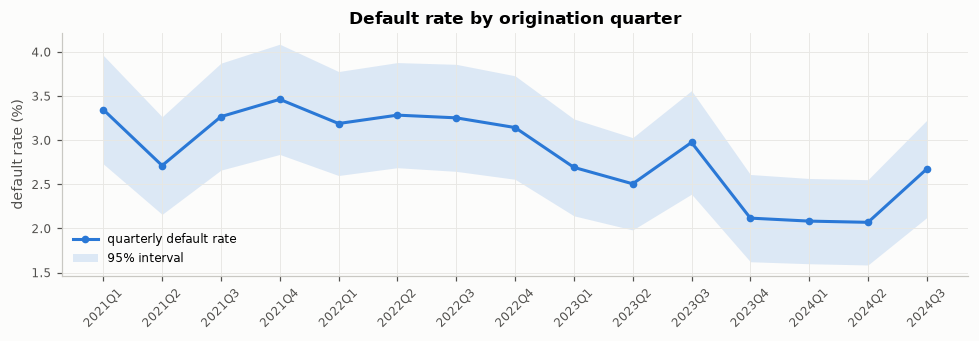

,loans,defaults,rate
vintage,,,
2021,13203,422,0.0320
2022,13552,436,0.0322
2023,13261,341,0.0257
2024,9984,227,0.0227


In [3]:
by_vintage = df.groupby(TIME).agg(loans=(TARGET, "size"), defaults=(TARGET, "sum"))
by_vintage["rate"] = by_vintage["defaults"] / by_vintage["loans"]
q = pd.PeriodIndex(pd.to_datetime(df["origination_date"]), freq="Q")
by_q = df.groupby(q)[TARGET].agg(["size", "sum"])
by_q["rate"] = by_q["sum"] / by_q["size"]
by_q["se"] = np.sqrt(by_q["rate"] * (1 - by_q["rate"]) / by_q["size"])

fig, ax = plt.subplots(figsize=(9, 3.2))
x = np.arange(len(by_q))
ax.plot(
    x,
    by_q["rate"] * 100,
    color=BLUE,
    marker="o",
    markersize=4,
    label="quarterly default rate",
)
ax.fill_between(
    x,
    (by_q["rate"] - 1.96 * by_q["se"]) * 100,
    (by_q["rate"] + 1.96 * by_q["se"]) * 100,
    color=BLUE,
    alpha=0.15,
    linewidth=0,
    label="95% interval",
)
ax.set_xticks(x, [str(p) for p in by_q.index], rotation=45)
ax.set_ylabel("default rate (%)")
ax.set_title("Default rate by origination quarter")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
by_year = df.groupby(df[TIME] // 100)[TARGET].agg(loans="size", defaults="sum")
by_year["rate"] = by_year["defaults"] / by_year["loans"]
by_year

The default rate is flat around 3.2% in 2021-22 and falls to 2.57% in 2023 and 2.27% in
January-September 2024. Quarterly rates in 2023Q4-2024Q2 sit below the 2021-22 band. Section 2.3
shows this is not a change in borrower mix.

### 2.2 Feature distributions and relationships with default

Default rate by decile of each numeric feature (placeholders removed first), and by level of
each categorical feature. The dashed line is the overall default rate.

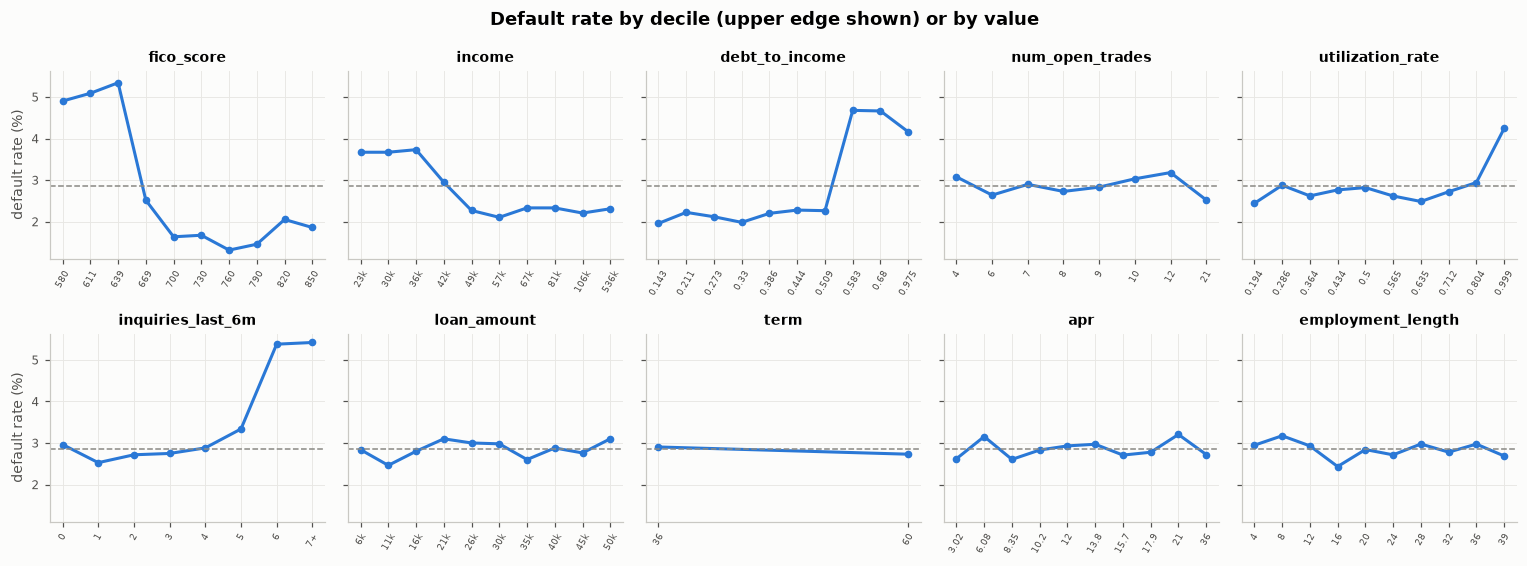

In [4]:
clean = clean_special_values(df)
num_cols = list(NUMERIC_INPUTS)
fig, axes = plt.subplots(2, 5, figsize=(14, 5.2), sharey=True)
base = df[TARGET].mean() * 100
for ax, col in zip(axes.ravel(), num_cols, strict=True):
    s = clean[col]
    if s.nunique() <= 12:
        s = s.clip(upper=7) if col == "inquiries_last_6m" else s  # 8-10 hold only 45 loans
        grp = clean.groupby(s)[TARGET].mean() * 100
        labels = [f"{v:g}" for v in grp.index]
        if col == "inquiries_last_6m":
            labels[-1] = "7+"
    else:
        bins = pd.qcut(s, 10, duplicates="drop")
        grp = clean.groupby(bins, observed=True)[TARGET].mean() * 100
        labels = [
            f"{iv.right / 1000:.0f}k" if iv.right > 999 else f"{iv.right:.3g}" for iv in grp.index
        ]
    ax.plot(range(len(grp)), grp.values, color=BLUE, marker="o", markersize=4)
    ax.axhline(base, color=GRAY, linestyle="--", linewidth=1)
    ax.set_xticks(range(len(grp)), labels, rotation=60, fontsize=6)
    ax.set_title(col, fontsize=9)
axes[0, 0].set_ylabel("default rate (%)")
axes[1, 0].set_ylabel("default rate (%)")
fig.suptitle("Default rate by decile (upper edge shown) or by value", fontweight="bold")
plt.tight_layout()
plt.show()

In [5]:
cat_rates = []
for col in [*CATEGORICAL_INPUTS, "term"]:
    g = df.groupby(col)[TARGET].agg(loans="size", defaults="sum")
    g["rate"] = g["defaults"] / g["loans"]
    g.index = [f"{col} = {v}" for v in g.index]
    cat_rates.append(g)
pd.concat(cat_rates)

,loans,defaults,rate
channel = Direct,24851,721,0.0290
channel = Mail,5058,145,0.0287
channel = Partner,20091,560,0.0279
product_type = Auto,9813,273,0.0278
product_type = Business,5084,141,0.0277
product_type = Debt_Consolidation,12664,343,0.0271
product_type = Home_Improvement,7391,229,0.0310
product_type = Personal,15048,440,0.0292
state = CA,7518,185,0.0246
state = FL,4903,152,0.0310


Four features carry almost all the signal, each as a step rather than a slope:
- FICO: about 5% below 650, under 2.5% above it.
- Debt-to-income: about 2% up to 0.5, about 4.5% above.
- Income: about 3.7% below roughly 40k, about 2.3% above.
- Utilization: rises only in the top decile (above 0.8).

Inquiries rise from 5 upward. Number of open trades, loan amount, term, APR and employment length
are flat. Channel, product and state move the rate by less than a percentage point. Steps favor
models that cut features into ranges: binned logistic regression and trees.

In [6]:
flags = pd.DataFrame(
    {
        "fico < 650": clean["fico_score"] < 650,
        "DTI > 0.5": clean["debt_to_income"] > 0.5,
        "income < 40k": clean["income"] < 40_000,
        "utilization > 0.8": clean["utilization_rate"] > 0.8,
    }
)
n_flags = flags.sum(axis=1)
flag_table = df.groupby(n_flags)[TARGET].agg(loans="size", defaults="sum")
flag_table["rate"] = flag_table["defaults"] / flag_table["loans"]
flag_table.index.name = "number of risk flags"
flag_table

,loans,defaults,rate
number of risk flags,,,
0,13485,84,0.0062
1,21631,561,0.0259
2,12021,564,0.0469
3,2686,190,0.0707
4,177,27,0.1525


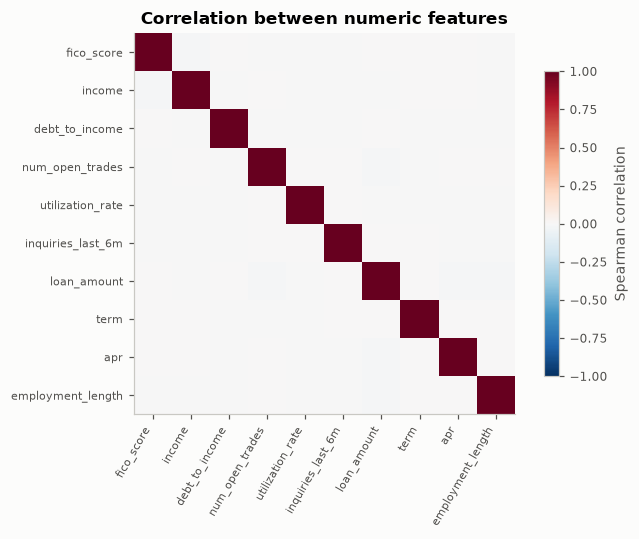

largest |correlation| between distinct features: 0.010


In [7]:
corr = clean[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols)), num_cols, rotation=60, ha="right", fontsize=7)
ax.set_yticks(range(len(num_cols)), num_cols, fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Correlation between numeric features")
plt.tight_layout()
plt.show()
off_diag = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print(f"largest |correlation| between distinct features: {off_diag.max().max():.3f}")

The numeric features are almost uncorrelated with each other (largest |Spearman| 0.010), which
is unusual for real bureau data (FICO and utilization usually move together) and suggests a
synthetic generator. The risk flags combine roughly additively: the default rate goes 0.62%,
2.59%, 4.69%, 7.07% and 15.25% for zero to four flags.

### 2.3 Drift across vintages

Is the lower default rate in 2023-24 a change in who borrows, or a change in how the same
borrowers perform?

In [8]:
year = df[TIME] // 100
mix = clean.groupby(year)[
    ["fico_score", "income", "debt_to_income", "utilization_rate", "apr", "loan_amount"]
].mean()
mix["share fico < 650"] = (clean["fico_score"] < 650).groupby(year).mean()
display(mix.round(3))
strata = pd.cut(
    clean["fico_score"],
    [0, 650, 750, 900],
    labels=["fico < 650", "650-749", "750+"],
    right=False,
)
within = df.groupby([strata, year], observed=True)[TARGET].mean().unstack() * 100
within.round(2)

,fico_score,income,debt_to_income,utilization_rate,apr,loan_amount,share fico < 650
vintage,,,,,,,
2021,700.615,58574.565,0.4,0.499,12.365,25624.391,0.313
2022,699.800,58671.964,0.4,0.502,12.336,25694.539,0.320
2023,699.901,58422.884,0.4,0.499,12.311,25527.514,0.315
2024,699.988,58888.586,0.4,0.498,12.317,25443.552,0.320


vintage,2021,2022,2023,2024
fico_score,,,,
fico < 650,5.85,5.78,4.57,3.79
650-749,1.47,1.86,1.34,1.50
750+,1.96,1.86,1.52,1.47


Borrower mix is flat across years: mean FICO about 700, income about 58.5k, DTI 0.40, APR
about 12.3%, and 31.3-32.0% of loans below 650 FICO. Default rates fell from 2021 to 2024 below
650 (5.85% to 3.79%) and above 750 (1.96% to 1.47%), but not in the 650-749 band. The data does
not say why. Candidates are economic conditions, collections or servicing changes, or outcomes
that are not yet final for the latest vintages.

Whatever the cause, a model calibrated on 2021-22 will over-predict 2024. Section 8 measures by
how much. These EDA tables use outcomes from the 2023 gap and the 2024 test window. So the fall
in default rates was known before the test pass. It shaped one expectation, calibration drift,
and no modeling choice.

## 3. Data quality, leakage and feature availability

### 3.1 Placeholder codes and informative missingness

In [9]:
rows = []
for col, code in SPECIAL_VALUES.items():
    miss = df[col] == code
    rows.append(
        {
            "column": col,
            "code": code,
            "rows": int(miss.sum()),
            "share": miss.mean(),
            "default rate if missing": df.loc[miss, TARGET].mean(),
            "default rate if present": df.loc[~miss, TARGET].mean(),
        }
    )
display(pd.DataFrame(rows))
miss_by_year = pd.DataFrame(
    {col: (df[col] == code).groupby(df[TIME] // 100).mean() for col, code in SPECIAL_VALUES.items()}
)
miss_by_year.index.name = "year"
print("Share of rows with the placeholder, by origination year:")
miss_by_year.round(4)

,column,code,rows,share,default rate if missing,default rate if present
0,fico_score,99999,2500,0.05,0.0416,0.0278
1,income,-1,1500,0.03,0.0593,0.0276
2,inquiries_last_6m,99,1000,0.02,0.0610,0.0279


Share of rows with the placeholder, by origination year:


,fico_score,income,inquiries_last_6m
year,,,
2021,0.0519,0.0303,0.0195
2022,0.0486,0.0301,0.0205
2023,0.0525,0.0288,0.0201
2024,0.0461,0.0310,0.0198


Each placeholder marks a missing value, and missingness predicts default: 4.16% when FICO is
missing vs 2.78%, 5.93% vs 2.76% for income, 6.10% vs 2.79% for inquiries. Median imputation
alone would erase that signal, so each column keeps a 0/1 missing flag and the value becomes
NaN. The share of placeholders is stable by origination year (FICO 4.6-5.3%, income 2.9-3.1%,
inquiries 2.0-2.1%), so the flags should not drift on their own.

### 3.2 Other quality checks

In [10]:
checks = {
    "employment_length > age - 16": int((df["employment_length"] > df["age"] - 16).sum()),
    "employment_length > age": int((df["employment_length"] > df["age"]).sum()),
    "apr at the 3.00 floor": int((df["apr"] == 3.0).sum()),
    "debt_to_income at the 0.01 floor": int((df["debt_to_income"] == 0.01).sum()),
    "utilization_rate outside [0, 1]": int((~df["utilization_rate"].between(0, 1)).sum()),
    "exact duplicate rows (excluding loan_id)": int(df.drop(columns="loan_id").duplicated().sum()),
}
emp_bad = df["employment_length"] > df["age"] - 16
checks["default rate, employment inconsistent vs consistent"] = (
    f"{df.loc[emp_bad, TARGET].mean():.2%} vs {df.loc[~emp_bad, TARGET].mean():.2%}"
)
pd.Series(checks, name="value").to_frame()

,value
employment_length > age - 16,13848
employment_length > age,3947
apr at the 3.00 floor,4988
debt_to_income at the 0.01 floor,33
"utilization_rate outside [0, 1]",0
exact duplicate rows (excluding loan_id),0
"default rate, employment inconsistent vs consistent",2.87% vs 2.85%


- `employment_length` exceeds `age - 16` in 13,848 rows (27.7%) and exceeds age itself in
  3,947. The field is unreliable, but those rows default at the same rate (2.87% vs 2.85%),
  and capping it at `age - 16` would bring the protected attribute into the model, so it is
  kept as reported and has little weight.
- 4,988 APRs (10%) sit at a 3.00 floor and 33 DTI values at a 0.01 floor: clipping in the source
  system. Kept.
- No NaN cells, no duplicates, utilization within [0, 1], `vintage` always matches
  `origination_date`.

### 3.3 Leakage: which columns exist at the decision?

The model is used when the application is decided. Any column recorded after that moment, or
derived from the outcome, cannot be an input. A single-column AUC near 0 or 1 is the
signature.

In [11]:
single_auc = {}
for col in [*NUMERIC_INPUTS, *LEAKAGE_COLUMNS, "age"]:
    s = clean[col] if col in clean else df[col]
    ok = s.notna()
    auc = binary_metrics(df.loc[ok, TARGET], s[ok].rank(pct=True))["roc_auc"]
    single_auc[col] = max(auc, 1 - auc)
ratio = df["total_payments_to_date"] / df["loan_amount"]
auc = binary_metrics(df[TARGET], ratio.rank(pct=True))["roc_auc"]
single_auc["total_payments_to_date / loan_amount"] = max(auc, 1 - auc)
leak_table = pd.Series(single_auc, name="single-column AUC (max of AUC, 1 - AUC)").sort_values(
    ascending=False
)
leak_table.to_frame()

,"single-column AUC (max of AUC, 1 - AUC)"
days_past_due_current,1.0000
sample_weight,1.0000
total_payments_to_date / loan_amount,1.0000
total_payments_to_date,0.9112
fico_score,0.6344
debt_to_income,0.5920
income,0.5586
utilization_rate,0.5291
inquiries_last_6m,0.5137
months_on_book,0.5079


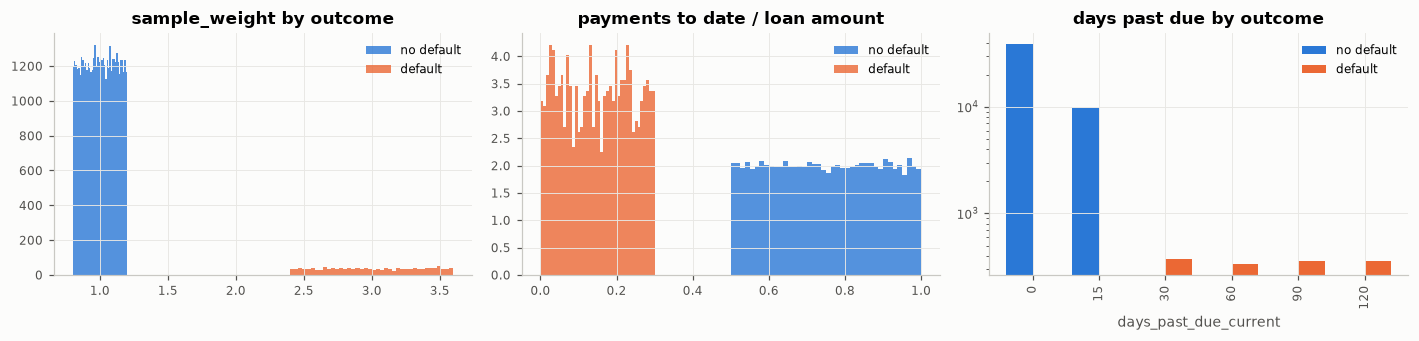

sample_weight range, non-defaults: 0.800-1.200
sample_weight range, defaults:     2.400-3.599


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
for label, color, name in [(0, BLUE, "no default"), (1, ORANGE, "default")]:
    sub = df[df[TARGET] == label]
    axes[0].hist(sub["sample_weight"], bins=40, color=color, alpha=0.8, label=name)
    axes[1].hist(
        sub["total_payments_to_date"] / sub["loan_amount"],
        bins=40,
        color=color,
        alpha=0.8,
        label=name,
        density=True,
    )
dpd = pd.crosstab(df["days_past_due_current"], df[TARGET])
dpd.plot.bar(ax=axes[2], color=[BLUE, ORANGE], width=0.8)
axes[0].set_title("sample_weight by outcome")
axes[1].set_title("payments to date / loan amount")
axes[2].set_title("days past due by outcome")
axes[2].legend(["no default", "default"])
axes[2].set_yscale("log")
for ax in axes[:2]:
    ax.legend()
plt.tight_layout()
plt.show()
w_good = df.loc[df[TARGET] == 0, WEIGHT]
w_bad = df.loc[df[TARGET] == 1, WEIGHT]
print(f"sample_weight range, non-defaults: {w_good.min():.3f}-{w_good.max():.3f}")
print(f"sample_weight range, defaults:     {w_bad.min():.3f}-{w_bad.max():.3f}")

In [13]:
mob = df.groupby(year)["months_on_book"].describe()[["mean", "min", "max"]]
mob["months since origination at 2024-09 (oldest vintage)"] = [
    (2024 - y) * 12 + 9 - 1 for y in mob.index
]
mob

,mean,min,max,months since origination at 2024-09 (oldest vintage)
vintage,,,,
2021,11.9837,0.0,24.0,44
2022,12.1560,0.0,24.0,32
2023,11.8759,0.0,24.0,20
2024,12.0814,0.0,24.0,8


- `sample_weight` is 0.80-1.20 for every non-default and 2.40-3.60 for every default, so a cut
  anywhere between 1.2 and 2.4 classifies every loan correctly. Defaults look like
  3 x U(0.8, 1.2), so the column was derived from the label. It can never be a feature, and
  evaluation stays unweighted. Section 6.3 tests it only as a training weight.
- `days_past_due_current` is 30 or more exactly when the loan defaulted (AUC 1.000).
  `total_payments_to_date` alone has AUC 0.911. Divided by `loan_amount` it separates perfectly:
  0.5-1.0 for non-defaults, 0.0-0.3 for defaults. Both describe repayment after origination.
- `months_on_book` carries no outcome signal (AUC 0.508), but it is recorded after origination.
  It is also uniform 0-24 in every vintage, including 2021 loans that would be 33-44 months old
  at a September 2024 snapshot, so it matches no snapshot date.

Section 6.3 shows what including these columns does: CV AUC 1.000.

## 4. Preprocessing and feature engineering

Every transformation is a step inside one scikit-learn `Pipeline`, so the saved model takes
the raw application exactly as the source system sends it (placeholder codes included) and
nothing is fit outside the training rows of a fold.

1. **Placeholder codes to NaN plus a missing flag** for `fico_score`, `income` and
   `inquiries_last_6m` (stateless).
2. **Engineered ratios** from the row's own columns: `loan_to_income` and
   `payment_to_income` (amortized monthly payment over monthly income; needs `apr`, so it is
   absent from the `no_apr` feature set).
3. **Categoricals** get fixed levels from configuration; an unseen level at scoring time
   becomes missing and is logged, not an error.
4. Model-specific encoding: the logistic regression imputes medians (fit on training rows),
   cuts each numeric column into quantile bins and one-hot encodes them (a scorecard-style
   model that captures step-shaped effects); LightGBM consumes the frame directly, handles
   missing values natively, and is constrained to be monotone in the directions credit
   policy expects (PD falls with FICO and income, rises with DTI, utilization, inquiries
   and the two ratios).

In [14]:
prep = make_preprocessor("full")
example = prep.transform(df[list(APPLICATION_COLUMNS)].head(5))
display(example)
pd.DataFrame(
    {name: [", ".join(cols)] for name, cols in FEATURE_SETS.items()},
    index=["raw input columns"],
).T

,fico_score,income,debt_to_income,num_open_trades,utilization_rate,inquiries_last_6m,loan_amount,term,apr,employment_length,channel,product_type,state,fico_score_missing,income_missing,inquiries_last_6m_missing,loan_to_income,payment_to_income
0,738.0,81758.0,0.0770,7,0.2484,0.0,31930,36,7.02,28,Direct,Personal,Other,0,0,0,0.3905,0.1447
1,818.0,21891.0,0.6960,8,0.5129,NaN,42735,36,11.90,5,Direct,Auto,IL,0,0,1,1.9522,0.7770
2,800.0,82072.0,0.1439,10,0.5875,1.0,17564,36,14.01,9,Partner,Home_Improvement,Other,0,0,0,0.2140,0.0878
3,657.0,40335.0,0.1670,8,0.2927,1.0,24951,60,10.88,14,Direct,Debt_Consolidation,Other,0,0,0,0.6186,0.1610
4,771.0,11733.0,0.0337,3,0.1871,0.0,46939,36,18.10,36,Partner,Personal,NY,0,0,0,4.0006,1.7380


,raw input columns
full,"fico_score, income, debt_to_income, num_open_t..."
no_apr,"fico_score, income, debt_to_income, num_open_t..."
fico_only,fico_score
leaky,"fico_score, income, debt_to_income, num_open_t..."


In [15]:
for family in ["logreg", "lgbm"]:
    steps = build_model(family, "full").steps
    print(f"{family}: " + " -> ".join(f"{name} ({type(est).__name__})" for name, est in steps))

logreg: prep (FunctionTransformer) -> encode (ColumnTransformer) -> model (LogisticRegression)
lgbm: prep (FunctionTransformer) -> model (MonotoneLGBM)


## 5. Validation strategy

Loans are ordered in time and the outcome takes 12 months to mature, so a random split would
let the model learn from loans originated after the ones it is tested on. The split is by
vintage, and the test window sits 12 months after the last training label, as it would in
production: on a decision date in January 2024, the latest vintage with a full 12-month
outcome is December 2022.

In [16]:
frames = pipeline.split_frames(df, DEFAULT_PROTOCOL)
split_summary = pd.DataFrame(
    {
        name: {
            "vintages": f"{f[TIME].min()}-{f[TIME].max()}",
            "loans": len(f),
            "defaults": int(f[TARGET].sum()),
            "default rate": f[TARGET].mean(),
        }
        for name, f in frames.items()
    }
).T
split_summary["use"] = [
    "cross-validation and tuning (4 expanding quarterly folds)",
    "calibration, cutoff, champion vs challenger",
    "secondary out-of-time check, scored once",
    "out-of-time test, scored once after everything is frozen",
]
display(split_summary)
assert split_summary["loans"].sum() == len(df)

folds = expanding_quarter_folds(frames["train"][TIME], frames["train"][TARGET])
fold_rows = []
for k, (tr, va) in enumerate(folds, start=1):
    t, v = frames["train"].iloc[tr], frames["train"].iloc[va]
    fold_rows.append(
        {
            "fold": k,
            "train vintages": f"{t[TIME].min()}-{t[TIME].max()}",
            "train loans": len(t),
            "validation vintages": f"{v[TIME].min()}-{v[TIME].max()}",
            "validation loans": len(v),
            "validation defaults": int(v[TARGET].sum()),
        }
    )
pd.DataFrame(fold_rows)

,vintages,loans,defaults,default rate,use
train,202101-202206,20062,644,0.0321,cross-validation and tuning (4 expanding quart...
val,202207-202212,6693,214,0.032,"calibration, cutoff, champion vs challenger"
gap,202301-202312,13261,341,0.0257,"secondary out-of-time check, scored once"
test,202401-202409,9984,227,0.0227,"out-of-time test, scored once after everything..."


,fold,train vintages,train loans,validation vintages,validation loans,validation defaults
0,1,202101-202106,6605,202107-202109,3306,108
1,2,202101-202109,9911,202110-202112,3292,114
2,3,202101-202112,13203,202201-202203,3418,109
3,4,202101-202203,16621,202204-202206,3441,113


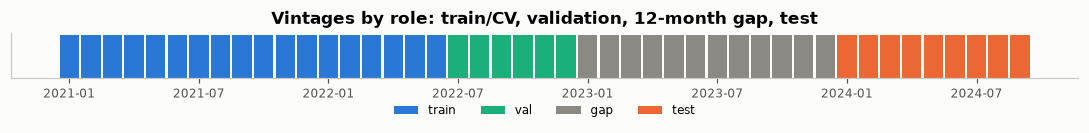

In [17]:
colors = {"train": BLUE, "val": AQUA, "gap": GRAY, "test": ORANGE}
fig, ax = plt.subplots(figsize=(10, 1.6))
for name, f in frames.items():
    v = sorted(f[TIME].unique())
    xs = [(x // 100 - 2021) * 12 + x % 100 - 1 for x in v]
    ax.bar(xs, 1, width=0.9, color=colors[name], label=name)
ax.set_yticks([])
ax.set_xticks(range(0, 45, 6), [f"{2021 + m // 12}-{m % 12 + 1:02d}" for m in range(0, 45, 6)])
ax.set_title("Vintages by role: train/CV, validation, 12-month gap, test")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.35))
ax.grid(False)
plt.tight_layout()
plt.show()

**Selection rule, written before any model ran (model card, 2026-11-18):** primary metric is
mean ROC AUC over the four expanding folds; among models that can give reasons for a decline
and respect the monotone directions, choose the simplest (lower tier, then fewer features)
within one standard error of the best. Tiers: 0 baselines, 1 logistic regression, 2
LightGBM. Accuracy is not used: predicting "no default" for everyone is 97% accurate and
useless. ROC AUC measures rank ordering, which is what approval decisions use; calibration
(Brier score, reliability) is checked separately because the PD level drives pricing and
loss forecasts.

## 6. Model development

### 6.1 Leaderboard

`scripts/run_experiments.py` ran every registered experiment: two baselines, the two tuned
families and four ablations, then (after the test pass) two fine searches and two reference
runs. Each has a manifest under `runs/` written before it ran. The notebook refits the
selectable configurations here and checks that their CV numbers match the leaderboard exactly.
The post-test recalibration (R10, section 8.1) changes no model, so it has a manifest but no
leaderboard row.

In [18]:
board = pd.read_csv(REPORTS / "leaderboard.csv")
display(
    board[
        [
            "run_id",
            "family",
            "feature_set",
            "weighted",
            "selectable",
            "cv_mean",
            "cv_se",
            "val_score",
            "trials",
            "stop_reason",
        ]
    ]
)

results = {}
for run_id in board.loc[board["selectable"] == "yes", "run_id"]:
    rec = json.loads((ROOT / "runs" / run_id / "result.json").read_text())
    cand = pipeline.Candidate(
        name=run_id,
        family=rec["family"],
        feature_set=rec["feature_set"],
        params=rec["params"],
        weighted=rec["weighted"],
    )
    results[run_id] = pipeline.train_candidate(cand, frames, seed=SEED)
    recorded = board.set_index("run_id").loc[run_id, "cv_mean"]
    assert abs(results[run_id].cv_mean - recorded) < 1e-5, (
        run_id,
        results[run_id].cv_mean,
        recorded,
    )
print("refit CV AUCs match the leaderboard for", len(results), "runs")

,run_id,family,feature_set,weighted,selectable,cv_mean,cv_se,val_score,trials,stop_reason
0,R00-base-rate,base_rate,full,no,yes,0.5000,0.0000,0.5000,1,none
1,R01-fico-only,logreg,fico_only,no,yes,0.6291,0.0104,0.6479,1,none
2,R02-logreg,logreg,full,no,yes,0.6812,0.0134,0.7126,35,plateau
3,R03-lgbm,lgbm,full,no,yes,0.7074,0.0070,0.7184,33,plateau
4,R04-logreg-no-apr,logreg,no_apr,no,yes,0.6834,0.0106,0.7134,1,none
5,R05-lgbm-no-apr,lgbm,no_apr,no,yes,0.7013,0.0062,0.7195,1,none
6,R06-lgbm-weighted,lgbm,full,yes,yes,0.7042,0.0063,0.7174,1,none
7,R07-lgbm-leaky,lgbm,leaky,no,no,1.0000,0.0000,1.0000,1,none
8,R08-lgbm-sensitivity,lgbm,full,no,no,0.7079,0.0066,0.7195,276,plateau
9,R09-lgbm-no-apr-sensitivity,lgbm,no_apr,no,no,0.7087,0.0067,0.7185,378,plateau


refit CV AUCs match the leaderboard for 7 runs


### 6.2 Tuning

Both families were tuned with TPE (Optuna) under a plateau stopping rule with a hard cap. The
logistic regression search converged (three seeds reach 0.6812). The first LightGBM search
(R03) did not: its minimum delta (0.0131) was coarser than the selection margin it informed,
and the frozen R05 reuses R03's parameters (64 trees at learning rate 0.011, a lightly fitted
model). Finer searches run after the test pass (R08, R09) put both LightGBM feature sets at
about 0.708, one standard error above R05. Two reference runs, also after the test pass and on
CV and validation only, bracket the tuned models: LightGBM with library defaults (R11) and a
scorecard with supervised (tree-chosen) bins (R12). None of the post-test runs is selectable.

In [19]:
tuning_rows = []
for run_id, what in [
    ("R02-logreg", "binned logistic, tuned"),
    ("R03-lgbm", "LightGBM, first search (unconverged)"),
    ("R05-lgbm-no-apr", "LightGBM no APR, R03 parameters (selected)"),
    ("R08-lgbm-sensitivity", "LightGBM, fine search (post-test)"),
    ("R09-lgbm-no-apr-sensitivity", "LightGBM no APR, fine search (post-test)"),
    ("R11-lgbm-no-apr-untuned", "LightGBM no APR, library defaults (post-test)"),
    ("R12-scorecard-no-apr", "supervised-bin scorecard no APR (post-test)"),
]:
    row = board.set_index("run_id").loc[run_id]
    tuning_rows.append(
        {
            "run": run_id,
            "configuration": what,
            "CV AUC": row["cv_mean"],
            "cv_se": row["cv_se"],
            "validation AUC": row["val_score"],
            "trials": row["trials"],
            "stop": row["stop_reason"],
        }
    )
r12 = json.loads((ROOT / "runs" / "R12-scorecard-no-apr" / "result.json").read_text())
print("R12 best grid point:", r12["params"])
rec_full = json.loads((ROOT / "runs" / "R08-lgbm-sensitivity" / "result.json").read_text())
rec_noapr = json.loads((ROOT / "runs" / "R09-lgbm-no-apr-sensitivity" / "result.json").read_text())
d = np.array(rec_full["fold_scores"]) - np.array(rec_noapr["fold_scores"])
print(
    f"R08 minus R09 per fold: {np.round(d, 4).tolist()}, "
    f"mean {d.mean():.4f}, se {d.std(ddof=1) / 2:.4f}"
)
pd.DataFrame(tuning_rows)

R12 best grid point: {'min_bin_fraction': 0.05, 'max_bins': 4, 'C': 0.01}
R08 minus R09 per fold: [0.0019, -0.0022, 0.002, -0.0051], mean -0.0008, se 0.0017


,run,configuration,CV AUC,cv_se,validation AUC,trials,stop
0,R02-logreg,"binned logistic, tuned",0.6812,0.0134,0.7126,35,plateau
1,R03-lgbm,"LightGBM, first search (unconverged)",0.7074,0.0070,0.7184,33,plateau
2,R05-lgbm-no-apr,"LightGBM no APR, R03 parameters (selected)",0.7013,0.0062,0.7195,1,none
3,R08-lgbm-sensitivity,"LightGBM, fine search (post-test)",0.7079,0.0066,0.7195,276,plateau
4,R09-lgbm-no-apr-sensitivity,"LightGBM no APR, fine search (post-test)",0.7087,0.0067,0.7185,378,plateau
5,R11-lgbm-no-apr-untuned,"LightGBM no APR, library defaults (post-test)",0.6725,0.0069,0.6822,1,none
6,R12-scorecard-no-apr,supervised-bin scorecard no APR (post-test),0.6804,0.0118,0.7079,9,none


- Tuning matters relative to LightGBM's defaults (R11, 0.672 CV). Those defaults (31 leaves,
  learning rate 0.1) are probably too flexible for 644 training defaults. Beyond that it
  matters little: the fine searches sit about one standard error above R05 (0.709 vs 0.701)
  and match it on validation (0.719 and 0.719 vs 0.719).
- The scorecard (R12) trails LightGBM by about 0.02 CV AUC and is close on validation (0.708 vs
  0.720). Its best grid point is at the edge of the grid (fewest bins, strongest penalty), so
  it is unconverged and its score is a lower bound. Default risk here is a set of steps (FICO
  650, DTI 0.5), which bins capture well, so a scorecard is a credible alternative where
  explainability rules require one.

### 6.3 Ablations: leakage, APR, sample weights

In [20]:
b = board.set_index("run_id")
abl = pd.DataFrame(
    [
        ("Leakage: add months_on_book, DPD, payments", "R03-lgbm", "R07-lgbm-leaky"),
        (
            "APR: drop apr (and payment_to_income), LightGBM",
            "R03-lgbm",
            "R05-lgbm-no-apr",
        ),
        (
            "APR: drop apr (and payment_to_income), logistic",
            "R02-logreg",
            "R04-logreg-no-apr",
        ),
        ("Weights: train with sample_weight", "R03-lgbm", "R06-lgbm-weighted"),
    ],
    columns=["ablation", "reference", "variant"],
)
abl["reference CV AUC"] = abl["reference"].map(b["cv_mean"])
abl["variant CV AUC"] = abl["variant"].map(b["cv_mean"])
abl["difference"] = abl["variant CV AUC"] - abl["reference CV AUC"]
abl["reference cv_se"] = abl["reference"].map(b["cv_se"])
display(abl)

paired = []
for ref, var in [
    ("R03-lgbm", "R05-lgbm-no-apr"),
    ("R03-lgbm", "R06-lgbm-weighted"),
    ("R03-lgbm", "R02-logreg"),
    ("R05-lgbm-no-apr", "R04-logreg-no-apr"),
]:
    d = np.array(results[ref].fold_scores) - np.array(results[var].fold_scores)
    paired.append(
        {
            "comparison": f"{ref} minus {var}",
            "per-fold differences": np.round(d, 4).tolist(),
            "mean": d.mean(),
            "paired se": d.std(ddof=1) / np.sqrt(len(d)),
        }
    )
pd.DataFrame(paired)

,ablation,reference,variant,reference CV AUC,variant CV AUC,difference,reference cv_se
0,"Leakage: add months_on_book, DPD, payments",R03-lgbm,R07-lgbm-leaky,0.7074,1.0000,0.2926,0.0070
1,"APR: drop apr (and payment_to_income), LightGBM",R03-lgbm,R05-lgbm-no-apr,0.7074,0.7013,-0.0061,0.0070
2,"APR: drop apr (and payment_to_income), logistic",R02-logreg,R04-logreg-no-apr,0.6812,0.6834,0.0022,0.0134
3,Weights: train with sample_weight,R03-lgbm,R06-lgbm-weighted,0.7074,0.7042,-0.0032,0.0070


,comparison,per-fold differences,mean,paired se
0,R03-lgbm minus R05-lgbm-no-apr,"[0.0115, 0.0029, 0.0026, 0.0073]",0.0061,0.0021
1,R03-lgbm minus R06-lgbm-weighted,"[0.0045, 0.0014, 0.0042, 0.0027]",0.0032,0.0007
2,R03-lgbm minus R02-logreg,"[0.0145, 0.0445, 0.0277, 0.0181]",0.0262,0.0067
3,R05-lgbm-no-apr minus R04-logreg-no-apr,"[0.0092, 0.0315, 0.0234, 0.0076]",0.0179,0.0058


- Adding the post-origination columns (leakage) lifts CV AUC from 0.707 to 1.000. That is
  what "suspiciously high predictive power" looks like.
- With R03's parameters, dropping APR (and `payment_to_income`, which needs it) costs
  0.0061 CV AUC, lower on all four folds. The fine searches (6.2) show this is an artifact
  of reusing parameters tuned with APR. Tuned on its own, the no-APR set reaches 0.7087 against
  0.7079 with APR, a paired difference of -0.0008 (se 0.0017). APR has no single-column signal
  either (AUC 0.503), so it adds no rank-ordering power. For the logistic regression the
  difference is +0.0022.
- Training with `sample_weight` (defaults up-weighted about 3x) lowers CV
  AUC by 0.0032 (all four folds) and inflates the mean predicted PD to 8.7% against a 3.2%
  default rate. The model trains unweighted, without resampling. Gradient boosting with a
  log-loss objective handles a 3% positive rate, and calibration is cleaner without
  weights.

### 6.4 Selection by the pre-registered rule

In [21]:
champion, challenger, explanation = pipeline.select_champion(list(results.values()))
print(explanation)
comparison = pipeline.compare_champion_challenger(champion, challenger, frames["val"][TARGET])
pd.Series(comparison).to_frame("validation, paired bootstrap (2,000 resamples)")

best cv 0.7074 (R03-lgbm), se 0.0070, floor 0.7004; 3 of 7 eligible; champion R05-lgbm-no-apr (cv 0.7013, tier 2, 12 features)


,"validation, paired bootstrap (2,000 resamples)"
diff,0.0010
lower,-0.0040
upper,0.0061
share_a_better,0.6530
champion_val_auc,0.7195
challenger_val_auc,0.7184


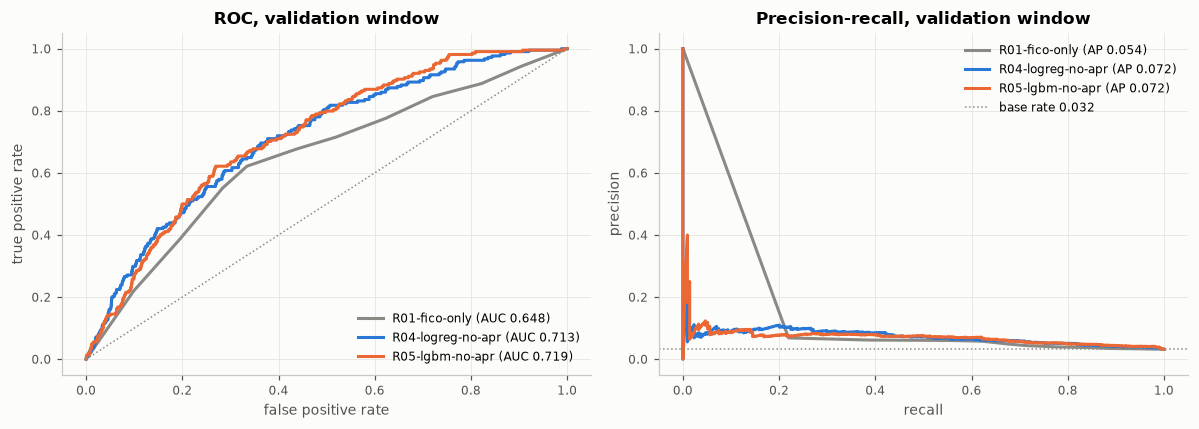

,roc_auc,gini,ks,pr_auc,brier,log_loss,mean_score,base_rate
R00-base-rate,0.5000,0.0000,0.0000,0.0320,0.0310,0.1415,0.0321,0.032
R01-fico-only,0.6479,0.2958,0.2872,0.0538,0.0306,0.1363,0.0318,0.032
R02-logreg,0.7126,0.4252,0.3328,0.0716,0.0304,0.1329,0.0321,0.032
R03-lgbm,0.7184,0.4369,0.3395,0.0694,0.0306,0.1354,0.0313,0.032
R04-logreg-no-apr,0.7134,0.4268,0.3334,0.0725,0.0304,0.1328,0.0320,0.032
R05-lgbm-no-apr,0.7195,0.4389,0.3522,0.0720,0.0305,0.1351,0.0313,0.032
R06-lgbm-weighted,0.7174,0.4347,0.3266,0.0686,0.0334,0.1602,0.0869,0.032


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
y_val = frames["val"][TARGET]
for run_id, color in [
    ("R01-fico-only", GRAY),
    ("R04-logreg-no-apr", BLUE),
    (champion.candidate.name, ORANGE),
]:
    s = results[run_id].val_scores
    fpr, tpr, _ = roc_curve(y_val, s)
    prec, rec_, _ = precision_recall_curve(y_val, s)
    m = binary_metrics(y_val, s)
    axes[0].plot(fpr, tpr, color=color, label=f"{run_id} (AUC {m['roc_auc']:.3f})")
    axes[1].plot(rec_, prec, color=color, label=f"{run_id} (AP {m['pr_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle=":", linewidth=1)
axes[1].axhline(
    y_val.mean(),
    color=GRAY,
    linestyle=":",
    linewidth=1,
    label=f"base rate {y_val.mean():.3f}",
)
axes[0].set(
    title="ROC, validation window",
    xlabel="false positive rate",
    ylabel="true positive rate",
)
axes[1].set(title="Precision-recall, validation window", xlabel="recall", ylabel="precision")
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()
pd.DataFrame({rid: binary_metrics(y_val, r.val_scores) for rid, r in results.items()}).T[
    ["roc_auc", "gini", "ks", "pr_auc", "brier", "log_loss", "mean_score", "base_rate"]
]

The rule picks **R05, LightGBM without APR**. The best CV AUC is 0.7074 (R03, with APR), and one
standard error below it is 0.7004. Three runs clear that floor, all LightGBM, and R05 has the
fewest features (12 vs 13). On validation the two are indistinguishable: champion minus
challenger AUC is 0.0010 (95% CI -0.0040 to 0.0061).

The margin was thin (0.0009) and rested on an unconverged search. The converged sensitivity
check gives the same family choice with room to spare: the APR-free set has the best CV AUC
(0.7087).

It also shows that the frozen R05 configuration is under-tuned. R05 scores 0.7013 against 0.7087
for R09, about one standard error. The tested model is R05, because changing it after the test
pass would need a new test window. R09 is itself lightly fitted (88 three-leaf trees), so the
next version should tune on log loss instead (section 13).

Leaving APR out is also the safer production choice. If APR comes from risk-based pricing, a
model that uses it would depend on the output of an earlier risk decision.

LightGBM beats the logistic regression in CV by 0.018 (paired standard error 0.006). On
validation alone they are close (0.7195 vs 0.7134).

## 7. Calibration and cutoff

The champion is calibrated on the validation window with Platt scaling (a two-parameter
logistic map; isotonic regression would overfit about 200 validation defaults). The cutoff
comes from the assumed economics in the model card: declining a good loan forfeits the
lifetime margin (10% of principal), approving a bad loan loses LGD x exposure (60%). That
puts the break-even PD at 0.10 / (0.10 + 0.60) = 14.3%. These are placeholders for the business's real
figures, so the approval-rate table shows the trade-off at other cutoffs. Everything in this
section is frozen before the test window is touched.

In [23]:
cal = pipeline.calibrate_and_cutoff(champion, frames, method="sigmoid", lgd=0.6, margin=0.10)
threshold = cal["breakeven_pd"]
print(
    f"Brier on validation: {cal['brier_before']:.5f} raw -> {cal['brier_after']:.5f} "
    "calibrated (in-sample for the calibrator)"
)
print(f"ECE on validation:   {cal['ece_before']:.5f} raw -> {cal['ece_after']:.5f} calibrated")
print(
    f"break-even PD cutoff: {threshold:.4f}; approval rate on validation at the cutoff: "
    f"{cal['approval_rate_at_breakeven']:.2%}"
)
display(cal["cutoff_table"])

frozen = {
    "champion": champion.candidate.name,
    "challenger": challenger.candidate.name if challenger else None,
    "calibration": "sigmoid (Platt) fit on validation 202207-202212",
    "threshold": threshold,
    "lgd": 0.6,
    "margin": 0.10,
}
frozen

Brier on validation: 0.03054 raw -> 0.03059 calibrated (in-sample for the calibrator)
ECE on validation:   0.01197 raw -> 0.00861 calibrated
break-even PD cutoff: 0.1429; approval rate on validation at the cutoff: 99.00%


,approval_rate,threshold,n_approved,bad_rate_approved,n_declined,bad_rate_declined,share_of_bads_declined
0,0.80,0.0396,5354,0.0217,1339,0.0732,0.4579
1,0.85,0.0438,5689,0.0237,1004,0.0787,0.3692
2,0.90,0.0513,6023,0.0267,670,0.0791,0.2477
3,0.95,0.0748,6358,0.0289,335,0.0896,0.1402


{'champion': 'R05-lgbm-no-apr',
 'challenger': 'R03-lgbm',
 'calibration': 'sigmoid (Platt) fit on validation 202207-202212',
 'threshold': 0.14285714285714288,
 'lgd': 0.6,
 'margin': 0.1}

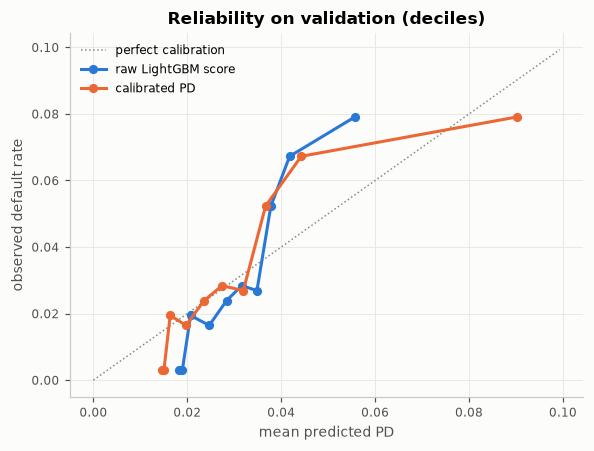

In [24]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
raw = calibration_table(y_val, champion.val_scores)
calt = calibration_table(y_val, cal["val_scores_calibrated"])
lim = max(raw["mean_score"].max(), calt["mean_score"].max(), calt["observed_rate"].max()) * 1.1
ax.plot(
    [0, lim],
    [0, lim],
    color=GRAY,
    linestyle=":",
    linewidth=1,
    label="perfect calibration",
)
ax.plot(
    raw["mean_score"],
    raw["observed_rate"],
    color=BLUE,
    marker="o",
    markersize=5,
    label="raw LightGBM score",
)
ax.plot(
    calt["mean_score"],
    calt["observed_rate"],
    color=ORANGE,
    marker="o",
    markersize=5,
    label="calibrated PD",
)
ax.set(
    title="Reliability on validation (deciles)",
    xlabel="mean predicted PD",
    ylabel="observed default rate",
)
ax.legend()
plt.tight_layout()
plt.show()

**A flaw found after the test pass.** The pipeline has no `decision_function`, so
scikit-learn's sigmoid calibration fits Platt scaling to the raw probability, not to its
log-odds. The map is then exponential in the raw score: it stretches the top (the top
validation decile goes from 5.6% raw to 9.0%, against 7.9% observed). At the bottom it lowers
the raw 1.8% only to 1.45%, while the bottom two deciles default at 0.3%. A raw-versus-
calibrated comparison on held-out data before freezing would have caught it. Section 8.1 tests
calibrators on log-odds.

## 8. Test evaluation of the frozen model

The frozen calibrated champion now scores the 2023 gap year and the 2024 test window, once
each. No decision below feeds back into the model. Brier skill compares the Brier score with a
constant at the training-window default rate, the best constant known at the decision date.
A positive value means the PD is more useful than that constant.

In [25]:
model = cal["calibrated_model"]
train_rate = float(frames["train"][TARGET].mean())
gap_eval = pipeline.evaluate_holdout(
    model,
    frames["gap"],
    "gap",
    threshold=threshold,
    seed=SEED,
    reference_rate=train_rate,
)
test_eval = pipeline.evaluate_holdout(
    model,
    frames["test"],
    "test",
    threshold=threshold,
    seed=SEED,
    reference_rate=train_rate,
)

summary_rows = {}
for name, ev in [("gap 2023", gap_eval), ("test 2024-01..09", test_eval)]:
    m = ev["metrics"]
    summary_rows[name] = {
        "loans": int(m["n"]),
        "defaults": int(m["n_pos"]),
        "ROC AUC": m["roc_auc"],
        "AUC 95% CI": f"{ev['auc_ci'][0]:.3f}-{ev['auc_ci'][1]:.3f}",
        "Gini": m["gini"],
        "KS": m["ks"],
        "PR AUC": m["pr_auc"],
        "Brier": m["brier"],
        # Brier of a constant c on a window with default rate p: p(1 - p) + (c - p)^2
        "Brier, constant at train rate": m["base_rate"] * (1 - m["base_rate"])
        + (train_rate - m["base_rate"]) ** 2,
        "Brier skill": ev["brier_skill"],
        "ECE": ev["ece"],
        "mean PD": m["mean_score"],
        "observed rate": m["base_rate"],
    }
summary_table = pd.DataFrame(summary_rows).T
summary_table

,loans,defaults,ROC AUC,AUC 95% CI,Gini,KS,PR AUC,Brier,"Brier, constant at train rate",Brier skill,ECE,mean PD,observed rate
gap 2023,13261,341,0.7124,0.689-0.737,0.4248,0.3213,0.057,0.0249,0.0251,0.0062,0.0088,0.032,0.0257
test 2024-01..09,9984,227,0.68,0.651-0.708,0.3601,0.3088,0.0374,0.0226,0.0223,-0.0149,0.0119,0.0321,0.0227


In [26]:
val_auc_ci = bootstrap_ci(
    y_val,
    cal["val_scores_calibrated"],
    lambda y, s: binary_metrics(y, s)["roc_auc"],
    seed=SEED,
)
print(f"validation AUC {val_auc_ci[0]:.4f} (95% CI {val_auc_ci[1]:.4f}-{val_auc_ci[2]:.4f})")
print(
    f"test AUC       {test_eval['metrics']['roc_auc']:.4f} "
    f"(95% CI {test_eval['auc_ci'][0]:.4f}-{test_eval['auc_ci'][1]:.4f})"
)
print(
    f"test at the cutoff: approval rate {test_eval['approval_rate']:.2%}, "
    f"bad rate among approved {test_eval['bad_rate_approved']:.2%}"
)
for name, ev, frame in [
    ("gap", gap_eval, frames["gap"]),
    ("test", test_eval, frames["test"]),
]:
    top = ev["calibration_table"].iloc[-1]
    s_ = positive_scores(model, frame)
    declined = s_ > threshold
    print(
        f"{name}: top decile predicted {top['mean_score']:.2%} "
        f"vs observed {top['observed_rate']:.2%}; "
        f"declined at the cutoff: {int(declined.sum())} loans, "
        f"{int(frame.loc[declined, TARGET].sum())} defaults"
    )

validation AUC 0.7195 (95% CI 0.6866-0.7505)
test AUC       0.6800 (95% CI 0.6507-0.7078)
test at the cutoff: approval rate 99.03%, bad rate among approved 2.26%
gap: top decile predicted 9.03% vs observed 6.18%; declined at the cutoff: 119 loans, 11 defaults
test: top decile predicted 9.09% vs observed 3.90%; declined at the cutoff: 97 loans, 4 defaults


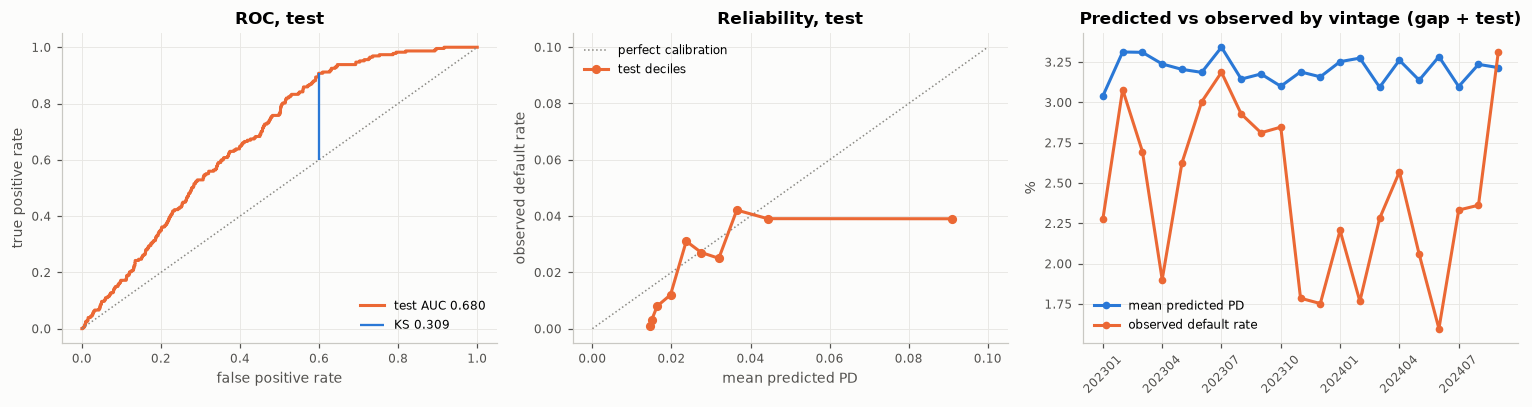

In [27]:
y_test = frames["test"][TARGET]
p_test = positive_scores(model, frames["test"])
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
fpr, tpr, _ = roc_curve(y_test, p_test)
axes[0].plot(fpr, tpr, color=ORANGE, label=f"test AUC {test_eval['metrics']['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], color=GRAY, linestyle=":", linewidth=1)
ks_idx = np.argmax(tpr - fpr)
axes[0].vlines(
    fpr[ks_idx],
    fpr[ks_idx],
    tpr[ks_idx],
    color=BLUE,
    linewidth=1.5,
    label=f"KS {tpr[ks_idx] - fpr[ks_idx]:.3f}",
)
axes[0].set(title="ROC, test", xlabel="false positive rate", ylabel="true positive rate")
axes[0].legend(loc="lower right")
ct = test_eval["calibration_table"]
lim = max(ct["mean_score"].max(), ct["observed_rate"].max()) * 1.1
axes[1].plot(
    [0, lim],
    [0, lim],
    color=GRAY,
    linestyle=":",
    linewidth=1,
    label="perfect calibration",
)
axes[1].plot(
    ct["mean_score"],
    ct["observed_rate"],
    color=ORANGE,
    marker="o",
    markersize=5,
    label="test deciles",
)
axes[1].set(
    title="Reliability, test",
    xlabel="mean predicted PD",
    ylabel="observed default rate",
)
axes[1].legend()
pv = pd.concat([gap_eval["per_vintage"], test_eval["per_vintage"]])
xv = np.arange(len(pv))
axes[2].plot(
    xv,
    pv["mean_pd"] * 100,
    color=BLUE,
    marker="o",
    markersize=4,
    label="mean predicted PD",
)
axes[2].plot(
    xv,
    pv["observed_rate"] * 100,
    color=ORANGE,
    marker="o",
    markersize=4,
    label="observed default rate",
)
axes[2].set_xticks(xv[::3], pv["vintage"].astype(str).iloc[::3], rotation=45)
axes[2].set(title="Predicted vs observed by vintage (gap + test)", ylabel="%")
axes[2].legend()
plt.tight_layout()
plt.show()

- **Ranking.** Test AUC is 0.680 (95% CI 0.651-0.708), against 0.719 on validation (CI
  0.687-0.751) and 0.712 in the 2023 gap year. The intervals overlap, and with 227 test
  defaults the drop is consistent with sampling noise plus the 2024 drift. It is not evidence
  of leakage: no feature uses another row's label. The test interval is the expected range for
  ranking next year's applications. Gini is 0.36 and KS 0.31.
- **The PD loses to a constant on test.** Brier skill is -1.5% on test and +0.6% in the gap
  year. A PD model that cannot beat the base rate on Brier is not ready for pricing.
- **Level.** The model was calibrated to 2022 default rates (3.2%) and predicts 3.21% on
  average in 2024, against 2.27% observed. The gap year shows the same pattern, milder: 3.20%
  vs 2.57%. The marginal input distributions did not move (section 9), so nothing in the
  inputs signaled the change.
- **Shape.** The PD is wrong at both ends. The bottom decile predicts 1.45% against 0.10%
  observed; the raw scores are no better there (section 8.1). The top predicts 9.0% vs 6.2% in
  the gap year and 9.1% vs 3.9% on test. Part of the top miss is drift (the top decile's
  observed rate fell from 7.9% on validation), and part is the calibrator flaw in section 7.
- **Decision.** The break-even cutoff (PD above 14.3%) declines about 1% of applicants. Those
  loans default far below break-even: 4 of 97 (4.1%) on test and 11 of 119 (9.2%) in the gap
  year. Under the assumed economics this cutoff turns away profitable loans, and it should not
  be used.
- **Stricter policy.** The cutoff table on validation shows the ranking power. At a 90% approval
  rate, the declined 10% default at 7.9% vs 2.7% for the approved, catching 25% of defaults.
- **Leaderboard.** The test score is recorded on R05 only (`reports/leaderboard.csv`). The test
  window was scored once with the frozen model. Two later looks are disclosed: one pipeline run
  with isotonic calibration (README), which informed no decision, and the registered post-hoc
  recalibration in section 8.1.

In [28]:
board.loc[:, "selected"] = "no"
board.loc[board["run_id"] == champion.candidate.name, "selected"] = "yes"
board.loc[board["run_id"] == champion.candidate.name, "test_score"] = round(
    test_eval["metrics"]["roc_auc"], 5
)
board.to_csv(REPORTS / "leaderboard.csv", index=False)
pred_out = frames["test"][["loan_id", TIME, TARGET]].assign(pd_calibrated=p_test)
pred_out.to_csv(REPORTS / "test_predictions.csv", index=False, float_format="%.10f")
print("leaderboard updated; test predictions saved for the reproducibility check")

leaderboard updated; test predictions saved for the reproducibility check


### 8.1 Post-test recalibration (v1.1, registered run R10)

This section is post-hoc. It was registered after the test pass (`runs/R10-calibration-v1.1/
manifest.md`, committed before the run) and its results are published whatever they show.
The base model is the frozen v1 pipeline. Only the calibrator changes, and it is chosen and
fit on data mature at a 2024-01 decision date (validation, 2022-H2):

- Candidates, simplest first: shift the log-odds (one parameter), intercept and slope on the
  log-odds (Platt done right), v1's sigmoid on the probability, isotonic.
- Selection: fit on 2022-07..09 and score 2022-10..12, then the reverse. Take the simplest
  method whose pooled out-of-fold Brier is within one paired standard error of the best.

Refitting the calibrator on 2023 would use labels that did not exist at a 2024-01 decision,
so it is not done here. It is the right step at deployment (section 13), with no test claim.
`scripts/recalibrate.py` produced the outputs, and the cells below read them back and check
the saved artifact.

In [29]:
r10 = json.loads((ROOT / "runs" / "R10-calibration-v1.1" / "result.json").read_text())
print(f"chosen: {r10['chosen']}; lowest out-of-fold Brier: {r10['best']}")
display(pd.DataFrame(r10["selection_table"]))
r10_summary = pd.concat(
    {w: pd.DataFrame(r10["summary"][w]).set_index("model") for w in ("gap", "test")}
)
r10_summary[["auc", "brier", "brier_skill", "ece", "mean_pd", "observed", "top_pred", "top_obs"]]

chosen: logit_intercept; lowest out-of-fold Brier: isotonic


,method,brier,log_loss,ece,diff_vs_best,se_vs_best,eligible
0,logit_intercept,0.0305,0.1352,0.0127,4.9696e-05,1.4234e-04,True
1,logit_platt,0.0305,0.1338,0.0086,4.1304e-05,8.4041e-05,True
2,sigmoid,0.0307,0.1349,0.0101,1.7732e-04,8.2428e-05,False
3,isotonic,0.0305,0.1376,0.0064,0.0000e+00,0.0000e+00,True


auc   brier  brier_skill     ece  mean_pd  observed  top_pred  top_obs
     model                                                                           
gap  raw    0.7124  0.0248       0.0128  0.0097   0.0313    0.0257    0.0557   0.0618
     v1     0.7124  0.0249       0.0062  0.0088   0.0320    0.0257    0.0903   0.0618
     v1.1   0.7124  0.0248       0.0126  0.0100   0.0320    0.0257    0.0569   0.0618
test raw    0.6800  0.0221       0.0074  0.0099   0.0313    0.0227    0.0557   0.0390
     v1     0.6800  0.0226      -0.0149  0.0119   0.0321    0.0227    0.0909   0.0390
     v1.1   0.6800  0.0222       0.0068  0.0103   0.0320    0.0227    0.0569   0.0390

v1.1 artifact reproduces its saved test PDs; v1 column matches the frozen model


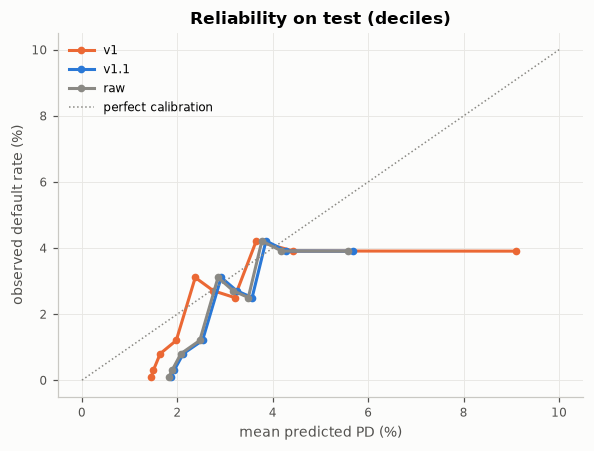

lowest-scored 20% of test loans: default rate 0.20% (overall 2.27%)
                                             Brier skill  bottom decile PD
v1                                               -0.0149            0.0145
v1.1                                              0.0068            0.0187
v1.1 + level shift fit on test (diagnostic)       0.0100            0.0132
isotonic fit on test (diagnostic)                 0.0144            0.0006
bottom decile observed: 0.0010


Brier skill 95% bootstrap CI: v1 -2.52% to -0.47%; v1.1 0.39% to 0.97%
highest v1.1 test PD: 11.29%; break-even 14.29%
validation cutoff table, v1.1 scores:


,approval_rate,threshold,n_approved,bad_rate_approved,n_declined,bad_rate_declined,share_of_bads_declined
0,0.80,0.0403,5354,0.0217,1339,0.0732,0.4579
1,0.85,0.0425,5689,0.0237,1004,0.0787,0.3692
2,0.90,0.0461,6023,0.0267,670,0.0791,0.2477
3,0.95,0.0545,6358,0.0289,335,0.0896,0.1402


In [30]:
v11_dir = ROOT / "models" / "pd-lgbm-no-apr-v1.1"
v11_pred = pd.read_csv(REPORTS / "test_predictions_v1.1.csv")
rescored = pipeline.score_applications(v11_dir, frames["test"][list(APPLICATION_COLUMNS)])
assert np.allclose(rescored.values, v11_pred["pd_v1_1"].values)
assert np.allclose(v11_pred["pd_v1"].values, p_test)
print("v1.1 artifact reproduces its saved test PDs; v1 column matches the frozen model")

fig, ax = plt.subplots(figsize=(5.5, 4.2))
for name, color in [("v1", ORANGE), ("v1.1", BLUE), ("raw", GRAY)]:
    t = pd.DataFrame(r10["evaluations"]["test"][name]["calibration_table"])
    ax.plot(
        t["mean_score"] * 100,
        t["observed_rate"] * 100,
        color=color,
        marker="o",
        markersize=4,
        label=name,
    )
ax.plot([0, 10], [0, 10], color=GRAY, linestyle=":", linewidth=1, label="perfect calibration")
ax.set(
    title="Reliability on test (deciles)",
    xlabel="mean predicted PD (%)",
    ylabel="observed default rate (%)",
)
ax.legend()
plt.tight_layout()
plt.show()

dec = pd.DataFrame(r10["evaluations"]["test"]["v1.1"]["calibration_table"])
low20 = (dec["observed_rate"].iloc[:2] * dec["n"].iloc[:2]).sum() / dec["n"].iloc[:2].sum()
print(f"lowest-scored 20% of test loans: default rate {low20:.2%} (overall {y_test.mean():.2%})")

# Diagnostics only: calibrators fit on the test labels and scored in-sample. They split the
# remaining error into level and shape; they are not models and choose nothing.
yt = v11_pred[TARGET].to_numpy()
pv1, pv11 = v11_pred["pd_v1"].to_numpy(), v11_pred["pd_v1_1"].to_numpy()
ref = r10["reference_rate"]


def skill(y: np.ndarray, q: np.ndarray) -> float:
    """Brier skill of q against the constant training default rate."""
    return 1 - np.mean((y - q) ** 2) / np.mean((y - ref) ** 2)


zt = logit(pv11)
shift = brentq(lambda c: (yt - expit(zt + c)).sum(), -5, 5)
level_only = expit(zt + shift)
iso_test = IsotonicRegression(out_of_bounds="clip").fit(pv11, yt).predict(pv11)
bottom = pd.qcut(pv11, 10, labels=False) == 0
print(
    pd.DataFrame(
        {
            "Brier skill": [skill(yt, q) for q in (pv1, pv11, level_only, iso_test)],
            "bottom decile PD": [q[bottom].mean() for q in (pv1, pv11, level_only, iso_test)],
        },
        index=[
            "v1",
            "v1.1",
            "v1.1 + level shift fit on test (diagnostic)",
            "isotonic fit on test (diagnostic)",
        ],
    ).round(4)
)
print(f"bottom decile observed: {yt[bottom].mean():.4f}")

rng = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    boot.append((skill(yt[i], pv1[i]), skill(yt[i], pv11[i])))
ci_lo, ci_hi = np.percentile(np.array(boot), [2.5, 97.5], axis=0)
print(
    f"Brier skill 95% bootstrap CI: v1 {ci_lo[0]:.2%} to {ci_hi[0]:.2%}; "
    f"v1.1 {ci_lo[1]:.2%} to {ci_hi[1]:.2%}"
)
print(
    f"highest v1.1 test PD: {v11_pred['pd_v1_1'].max():.2%}; break-even {r10['breakeven_pd']:.2%}"
)
print("validation cutoff table, v1.1 scores:")
pd.DataFrame(r10["validation"]["cutoff_table"])

- **Selection.** Only v1's method failed the rule. The two log-odds methods and isotonic are
  within one standard error of each other on 214 validation defaults, so the rule had no power
  to prefer a richer shape and took the simplest: a single log-odds shift.
- **Result.** Test Brier skill moves from -1.5% (v1) to +0.7% (v1.1), and the gap year from
  +0.6% to +1.3%. The top test decile now predicts 5.7% against 3.9% observed, down from 9.1%.
  The bootstrap intervals (printed above) do not overlap zero in either case. The uncalibrated
  scores do as well as v1.1, so v1's calibrator caused the loss.
- **Expectation not met at the bottom.** The manifest expected the shape fix to help the bottom
  of the scale. It did not: the bottom decile predicts 1.87% against 0.10%, worse than v1's
  1.45%. The reason is the selection rule's outcome, not the scores. A one-parameter log-odds
  shift cannot change shape by construction, and the rule picked it because the richer methods
  were not better on 214 validation defaults. The raw bottom deciles are distinct (1.82%,
  1.89%, 2.07%), and isotonic fit on test labels brings the bottom decile to 0.06%.
- **What is left, level or shape.** The diagnostics above fit calibrators on the test labels
  themselves. A level shift alone reaches 1.0% skill and isotonic 1.4%, against 0.7% for v1.1.
  Roughly half of the remaining gap is the 2024 level, which outcome monitoring has to catch,
  and half is shape, which a richer calibrator fit on more defaults could recover. Both
  figures are in-sample on test, so they are references, not bounds.
- **Cutoff.** No v1.1 PD reaches the 14.3% break-even, so that cutoff declines nobody. Under the
  assumed economics no applicant is unprofitable on expected loss. The score's use is ranking:
  pricing, limits, or a policy cutoff set by approval rate (table above).

## 9. Stability and segments

PSI of the calibrated score against the training window:


,PSI
val,0.0014
gap,0.0006
test,0.0007


,feature,psi
0,employment_length,0.0019
1,loan_amount,0.0015
2,debt_to_income,0.0014
3,utilization_rate,0.0013
4,apr,0.0011
5,income,0.0010
6,num_open_trades,0.0007
7,fico_score,0.0005
8,inquiries_last_6m,0.0005
9,term,0.0001


,PSI train vs test
channel,7.3997e-05
product_type,1.5351e-04
state,1.1229e-03


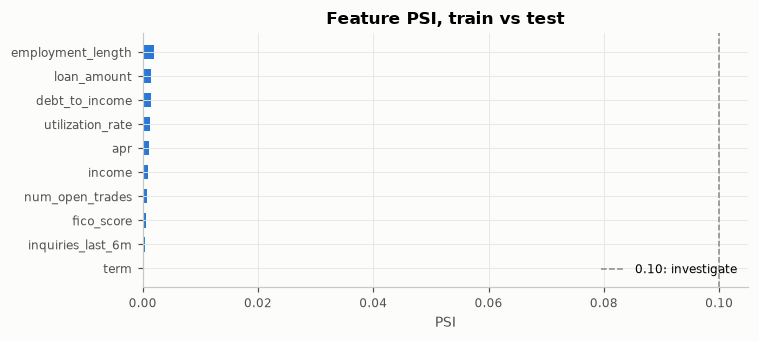

In [31]:
stab = pipeline.stability_report(model, frames)
print("PSI of the calibrated score against the training window:")
display(pd.Series(stab["score_psi"]).to_frame("PSI"))
display(stab["feature_psi"])


def category_psi(expected: pd.Series, actual: pd.Series) -> float:
    """PSI over category shares, with empty shares floored at 1e-6."""
    e = expected.value_counts(normalize=True)
    a = actual.value_counts(normalize=True).reindex(e.index, fill_value=0)
    e, a = e.clip(lower=1e-6), a.clip(lower=1e-6)
    return float(((a - e) * np.log(a / e)).sum())


cat_psi = pd.Series(
    {c: category_psi(frames["train"][c], frames["test"][c]) for c in CATEGORICAL_INPUTS},
    name="PSI train vs test",
)
display(cat_psi.to_frame())
fig, ax = plt.subplots(figsize=(7, 3.2))
fp = stab["feature_psi"]
ax.barh(fp.iloc[:, 0].astype(str), fp.iloc[:, 1], color=BLUE, height=0.6)
ax.axvline(0.1, color=GRAY, linestyle="--", linewidth=1, label="0.10: investigate")
ax.invert_yaxis()
ax.set(title="Feature PSI, train vs test", xlabel="PSI")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [32]:
MIN_ROWS, MIN_DEFAULTS = 1000, 30
test_df = frames["test"].assign(pd_calibrated=p_test)
test_clean = clean_special_values(test_df)
test_df["fico band"] = pd.cut(
    test_clean["fico_score"],
    [0, 650, 700, 750, 900],
    right=False,
    labels=["<650", "650-699", "700-749", "750+"],
)
test_df["fico band"] = test_df["fico band"].cat.add_categories("missing").fillna("missing")
overall_auc = test_eval["metrics"]["roc_auc"]
seg_rows, not_scored = [], []
for col in ["channel", "product_type", "state", "term", "fico band"]:
    for level, g in test_df.groupby(col, observed=True):
        n, d = len(g), int(g[TARGET].sum())
        if n < MIN_ROWS or d < MIN_DEFAULTS or g[TARGET].nunique() < 2:
            not_scored.append(f"{col} = {level} ({n} loans, {d} defaults)")
            continue
        point, lo, hi = bootstrap_ci(
            g[TARGET],
            g["pd_calibrated"],
            lambda y, s: binary_metrics(y, s)["roc_auc"],
            n_boot=500,
            seed=SEED,
        )
        se = (hi - lo) / (2 * 1.96)
        seg_rows.append(
            {
                "segment": f"{col} = {level}",
                "loans": n,
                "defaults": d,
                "AUC": point,
                "AUC se": se,
                "mean PD": g["pd_calibrated"].mean(),
                "observed": g[TARGET].mean(),
                "weak": point < overall_auc - se,
            }
        )
seg = pd.DataFrame(seg_rows)
display(seg)
print("Not scored (below 1,000 loans or 30 defaults):")
print("\n".join(not_scored) if not_scored else "none")

,segment,loans,defaults,AUC,AUC se,mean PD,observed,weak
0,channel = Direct,4968,114,0.6446,0.0201,0.0327,0.0229,True
1,channel = Partner,4026,90,0.7266,0.0215,0.0313,0.0224,False
2,product_type = Auto,1939,44,0.6609,0.0334,0.0322,0.0227,False
3,product_type = Debt_Consolidation,2516,53,0.6767,0.0282,0.0313,0.0211,False
4,product_type = Home_Improvement,1496,40,0.6719,0.0367,0.0315,0.0267,False
5,product_type = Personal,3027,71,0.6790,0.0230,0.0326,0.0235,False
6,state = Other,3749,80,0.7022,0.0242,0.0312,0.0213,False
7,state = TX,1219,31,0.6649,0.0428,0.0327,0.0254,False
8,term = 36,7003,163,0.6777,0.0171,0.0320,0.0233,False
9,term = 60,2981,64,0.6845,0.0260,0.0322,0.0215,False


Not scored (below 1,000 loans or 30 defaults):
channel = Mail (990 loans, 23 defaults)
product_type = Business (1006 loans, 19 defaults)
state = CA (1484 loans, 22 defaults)
state = FL (950 loans, 23 defaults)
state = GA (845 loans, 27 defaults)
state = IL (805 loans, 22 defaults)
state = NY (932 loans, 22 defaults)
fico band = 650-699 (1563 loans, 28 defaults)
fico band = 700-749 (1576 loans, 19 defaults)
fico band = missing (460 loans, 12 defaults)


- **Population stability.**
  - Every numeric input has PSI below 0.002.
  - The categorical inputs are below 0.002 too (state 0.0011).
  - The score's PSI against the training window is below 0.002 for validation, gap and test.
  - These cover booked loans and marginal distributions only.
  - Within those limits the booked population did not move, and population measures did not
    flag the 2024 change. Monitoring needs outcome measures (early delinquency, calibration on
    maturing vintages) as well.
- **Weak segments** (AUC below the overall test AUC by more than the segment's bootstrap
  standard error):
  - FICO below 650: AUC 0.540. FICO's contribution is flat below 650 (section 10), so ranking
    inside the band relies on weaker features. This is also where default rates moved most in
    2024.
  - Channel Direct: AUC 0.645 vs 0.727 for Partner. Worth a look at how Direct applications
    differ (self-reported fields, verification).
- **Not scored.** These fall below 1,000 loans or 30 defaults on the test window, so they are
  listed, not scored:
  - five states (CA, FL, GA, IL, NY)
  - channel Mail and product Business
  - FICO bands 650-699 and 700-749
  - loans with FICO missing (460 loans, 12 defaults)

## 10. Interpretation

LightGBM computes exact TreeSHAP contributions natively (`pred_contrib=True`), in log-odds of
the raw model. The Platt calibration is monotone, so it does not change the ranking of
reasons.

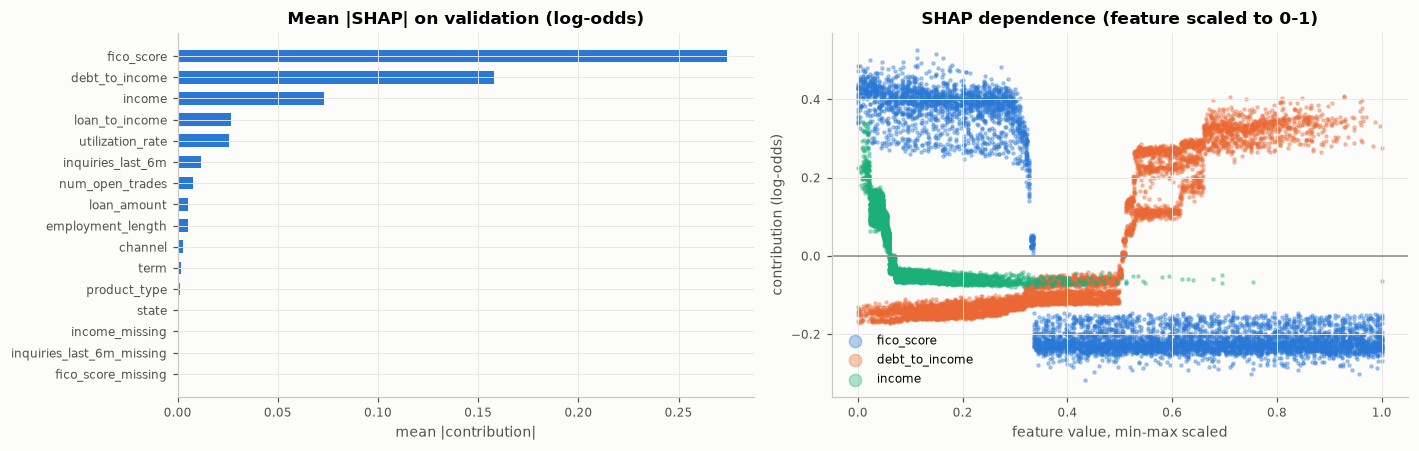

In [33]:
base_pipe = champion.model
Xt_val = base_pipe.named_steps["prep"].transform(frames["val"])
booster = base_pipe.named_steps["model"].booster_
contrib = booster.predict(Xt_val, pred_contrib=True)
shap_vals = pd.DataFrame(contrib[:, :-1], columns=Xt_val.columns)
importance = shap_vals.abs().mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].barh(importance.index, importance.values, color=BLUE, height=0.6)
axes[0].invert_yaxis()
axes[0].set(title="Mean |SHAP| on validation (log-odds)", xlabel="mean |contribution|")
for col, color in [("fico_score", BLUE), ("debt_to_income", ORANGE), ("income", AQUA)]:
    x = Xt_val[col].astype(float)
    xr = (x - x.min()) / (x.max() - x.min())
    axes[1].scatter(xr, shap_vals[col], s=4, alpha=0.35, color=color, label=col)
axes[1].axhline(0, color=GRAY, linewidth=1)
axes[1].set(
    title="SHAP dependence (feature scaled to 0-1)",
    xlabel="feature value, min-max scaled",
    ylabel="contribution (log-odds)",
)
axes[1].legend(markerscale=4)
plt.tight_layout()
plt.show()

In [34]:
fold_imp = []
for k, (tr, va) in enumerate(folds, start=1):
    m = build_model(
        champion.candidate.family,
        champion.candidate.feature_set,
        champion.candidate.params,
        seed=SEED,
    )
    m.fit(frames["train"].iloc[tr], frames["train"][TARGET].iloc[tr])
    xt = m.named_steps["prep"].transform(frames["train"].iloc[va])
    c = m.named_steps["model"].booster_.predict(xt, pred_contrib=True)[:, :-1]
    fold_imp.append(pd.Series(np.abs(c).mean(axis=0), index=xt.columns, name=f"fold {k}"))
fold_imp = pd.concat(fold_imp, axis=1)
rho = [
    spearmanr(fold_imp.iloc[:, i], fold_imp.iloc[:, j]).statistic
    for i in range(4)
    for j in range(i + 1, 4)
]
print(
    "Spearman rank correlation of feature importance between folds: "
    f"min {min(rho):.3f}, median {np.median(rho):.3f}"
)
fold_imp.rank(ascending=False).astype(int).sort_values("fold 4")

Spearman rank correlation of feature importance between folds: min 0.968, median 0.982


,fold 1,fold 2,fold 3,fold 4
fico_score,1,1,1,1
debt_to_income,2,2,2,2
income,3,3,3,3
utilization_rate,4,5,4,4
inquiries_last_6m,5,4,5,5
loan_to_income,7,6,6,6
employment_length,8,7,7,7
loan_amount,6,8,8,8
num_open_trades,9,9,9,9
term,12,13,11,10


In [35]:
declined = np.where(cal["val_scores_calibrated"] > np.quantile(cal["val_scores_calibrated"], 0.99))[
    0
][:1]
i = int(declined[0])
reasons = shap_vals.iloc[i].sort_values(ascending=False).head(4)
print(
    f"Example high-risk applicant (validation row {i}): "
    f"calibrated PD {cal['val_scores_calibrated'][i]:.3f}"
)
display(Xt_val.iloc[i][reasons.index].to_frame("value").assign(contribution=reasons.values))

Example high-risk applicant (validation row 17): calibrated PD 0.197


,value,contribution
fico_score,579.0,0.4335
debt_to_income,0.7996,0.3898
income,21356.0,0.1175
num_open_trades,14,0.0456


- **Importance.** FICO, DTI and income dominate, followed by loan-to-income, utilization and
  inquiries, matching the decile plots. The ranking is stable across the four CV folds (Spearman
  correlation at least 0.968), and the top three are in the same order on every fold.
- **Shape.** The dependence plot shows the steps the data has. FICO contributes about +0.4
  log-odds below 650 and about -0.2 above. DTI jumps at 0.5. Income contributes positive risk
  only at the low end.
- **Missing flags.** These get almost no weight: LightGBM routes NaN directly, so the flags are
  redundant for this model. They would matter for the logistic regression.
- **Reason codes.** For an individual decision, the largest positive contributions give the
  reasons. The example applicant (PD 0.197, above the cutoff) would get "credit score",
  "debt-to-income ratio" and "income" as the adverse-action reasons. With monotone constraints,
  a higher FICO or lower DTI never raises the PD, which makes these reasons consistent.

## 11. Sensitive attributes

Age is a protected basis under ECOA/Reg B and is not a model input. The check below asks
whether the model's decisions still differ by age band through correlated inputs.

In [36]:
age_band = pd.cut(
    test_df["age"],
    [20, 30, 40, 50, 60, 75],
    labels=["21-30", "31-40", "41-50", "51-60", "61-74"],
)
fair = test_df.groupby(age_band, observed=True).agg(
    loans=(TARGET, "size"),
    observed_rate=(TARGET, "mean"),
    mean_pd=("pd_calibrated", "mean"),
    approval_rate=("pd_calibrated", lambda s: (s <= threshold).mean()),
)
ct_val = cal["cutoff_table"].set_index("approval_rate")["threshold"]
for rate in (0.80, 0.90):
    fair[f"approved at {rate:.0%} policy"] = test_df.groupby(age_band, observed=True)[
        "pd_calibrated"
    ].apply(lambda s, t=ct_val[rate]: (s <= t).mean())
fair["defaults"] = test_df.groupby(age_band, observed=True)[TARGET].sum()
fair["predicted / observed"] = fair["mean_pd"] / fair["observed_rate"]
display(fair)
rho_age = spearmanr(test_df["age"], test_df["pd_calibrated"]).statistic
print(f"Spearman correlation between age and predicted PD on test: {rho_age:.3f}")

,loans,observed_rate,mean_pd,approval_rate,approved at 80% policy,approved at 90% policy,defaults,predicted / observed
age,,,,,,,,
21-30,1817,0.0220,0.0327,0.9906,0.7920,0.8806,40,1.4833
31-40,1827,0.0208,0.0308,0.9945,0.8134,0.9075,38,1.4825
41-50,1851,0.0243,0.0331,0.9881,0.7909,0.8925,45,1.3630
51-60,1867,0.0198,0.0318,0.9898,0.8072,0.9127,37,1.6032
61-74,2622,0.0256,0.0320,0.9889,0.8013,0.9069,67,1.2509


Spearman correlation between age and predicted PD on test: 0.003


**Age.** There is no evidence that the model ranks by age through other inputs:
- The Spearman correlation between age and predicted PD is 0.003.
- At the approval policies the cutoff table makes realistic, approval rates are close across
  age bands: 79.1-81.4% at the 80% policy and 88.1-91.3% at the 90% policy.
- Approval at the break-even cutoff (98.8-99.5%) says little, because it declines only 1%.
- Over-prediction differs by band: predicted/observed runs from 1.25 (ages 61-74) to 1.60
  (51-60). With 37-67 defaults per band these ratios are noisy, and calibration by age should
  be watched after recalibration.

**State.** `state` is an input with a weak effect (CA 2.46% to GA 3.23% overall). A fair-lending
review should confirm that geography is acceptable as a factor, since it can proxy for protected
groups.

## 12. Packaging and scoring

The calibrated pipeline is saved as one object with its metadata (input schema, split
protocol, data hash, threshold, metrics, library versions). The input schema is the 12 raw
application columns the model uses, so scoring does not need APR. `score_applications` checks
the schema before scoring, and the test suite reloads the artifact and reproduces the test
predictions above. The timing below measures one application through the full pipeline.

In [37]:
artifact_dir = ROOT / "models" / "pd-lgbm-no-apr-v1"
if artifact_dir.exists():
    logging.getLogger(__name__).warning(
        "replacing existing artifact %s", artifact_dir.relative_to(ROOT)
    )
    shutil.rmtree(artifact_dir)
pipeline.package_model(
    model,
    artifact_dir,
    candidate=champion.candidate,
    metrics={
        "cv_mean": champion.cv_mean,
        "cv_se": champion.cv_se,
        "val_auc": champion.val_auc,
        "test": {k: v for k, v in test_eval["metrics"].items()},
        "test_auc_ci": list(test_eval["auc_ci"]),
        "gap": {k: v for k, v in gap_eval["metrics"].items()},
    },
    data_hash=data_hash,
    protocol=DEFAULT_PROTOCOL,
    threshold=threshold,
    extra={"calibration": frozen["calibration"], "lgd": 0.6, "margin": 0.10},
)
scored = pipeline.score_applications(artifact_dir, frames["test"][list(APPLICATION_COLUMNS)])
assert np.allclose(scored.values, p_test)
print("artifact reloads and reproduces the test PDs exactly")

import time

loaded, _ = load_artifact(artifact_dir)
one = frames["test"][list(FEATURE_SETS["no_apr"])].iloc[[0]]
timings = []
for _ in range(200):
    t0 = time.perf_counter()
    loaded.predict_proba(one)
    timings.append((time.perf_counter() - t0) * 1000)
print(
    f"single-application scoring latency: median {np.median(timings):.1f} ms, "
    f"p99 {np.percentile(timings, 99):.1f} ms (200 calls, this laptop)"
)
print(
    json.dumps(
        json.loads((artifact_dir / "metadata.json").read_text())["library_versions"],
        indent=1,
    )
)

artifact reloads and reproduces the test PDs exactly


single-application scoring latency: median 2.2 ms, p99 2.8 ms (200 calls, this laptop)
{
 "joblib": "1.6.0",
 "lightgbm": "4.7.0",
 "numpy": "2.5.5",
 "pandas": "3.1.1",
 "python": "3.12.13",
 "scikit-learn": "1.9.1"
}


In [38]:
try:
    pipeline.score_applications(
        artifact_dir,
        frames["test"][list(APPLICATION_COLUMNS)].drop(columns=["fico_score"]),
    )
except Exception as err:  # demonstration of the schema check; the error type is printed
    print(f"{type(err).__name__}: {err}")

SchemaError: missing columns: ['fico_score']


## 13. Summary and recommendations

**The model ranks, but its PD does not yet price.** Ranking held out of time (test AUC 0.680;
the lowest-scored 20% default at 0.2% against 2.3% overall). The frozen v1 PD loses to a
constant on test Brier (skill -1.5%). The calibrator was an error. A post-hoc v1.1 chosen on
2022 data removes its top-end stretch (+0.7%, a second look at the test window). What remains
is about half the 2024 level shift, which outcome monitoring has to catch, and half shape at
the bottom of the scale, which a richer calibrator fit on more defaults could recover.

### Key findings

| Topic | Finding |
|---|---|
| Leakage | `days_past_due_current`, `sample_weight` and payments-to-date / loan amount separate defaults perfectly. `months_on_book` is post-origination. All excluded; including them gives CV AUC 1.000. |
| Placeholders | FICO 99999 (2,500), income -1 (1,500), inquiries 99 (1,000). Missingness raises default risk 1.5-2.2x. Kept as NaN plus flags. |
| Other quality | `employment_length` is impossible for the borrower's age in 27.7% of rows. APR is clipped at 3.00 for 10%. Numeric features are nearly uncorrelated. |
| Signal | Four step-shaped drivers (FICO < 650, DTI > 0.5, income < 40k, utilization > 0.8) carry almost everything. APR adds nothing once tuned for. |
| Drift | Default rates fell from 3.2% (2021-22) to 2.3% (2024), concentrated below FICO 650, while input distributions stayed stable (PSI < 0.002). Cause not established. |
| Calibration | v1's Platt scaling was fit on the probability, not the log-odds. It stretched the top of the scale, and the PD lost to a constant on test. A log-odds shift chosen on 2022 data (v1.1) fixes the stretch. |

### Model performance

| Model | CV AUC (4 folds) | Validation AUC | Test AUC |
|---|---|---|---|
| Base rate | 0.500 | 0.500 | not scored |
| FICO only (binned logistic) | 0.629 | 0.648 | not scored |
| Binned logistic regression, no APR | 0.683 | 0.713 | not scored |
| LightGBM with APR, R03 parameters (challenger) | 0.707 | 0.718 | not scored |
| **LightGBM without APR, R03 parameters (selected, R05)** | **0.701** | **0.719** | **0.680 (0.651-0.708)** |
| LightGBM without APR, converged search (R09, after the test pass) | 0.709 | 0.719 | not scored |
| LightGBM without APR, library defaults (R11, after the test pass) | 0.672 | 0.682 | not scored |
| Supervised-bin scorecard, no APR (R12, after the test pass, unconverged grid) | 0.680 | 0.708 | not scored |

The selected model's test results (ranking is the same for both calibrators; v1.1 is post-hoc):

| Measure | v1 (frozen) | v1.1 (R10) |
|---|---|---|
| Gini / KS | 0.36 / 0.31 | 0.36 / 0.31 |
| Brier score | 0.02264 | 0.02216 |
| Brier skill vs constant at the training rate | -1.5% | +0.7% |
| Mean predicted PD (observed 2.27%) | 3.21% | 3.20% |
| Top decile, predicted vs observed | 9.1% vs 3.9% | 5.7% vs 3.9% |
| Bottom decile, predicted vs observed | 1.45% vs 0.10% | 1.87% vs 0.10% |

### Limitations and assumptions

- **Label maturity.** Labels are treated as final. If the data were cut at 2024-09, loans from
  2023-10 onward could not have a full 12-month outcome. Observed test rates do not fall toward
  the most recent vintages (202409 has the highest, 3.31%), but this is an assumption to
  confirm, not a finding.
- **Selection bias.** Only booked loans have outcomes. The model is trained on approved
  applicants and would score all applicants, and no reject inference was possible.
- **Calibration.** Both calibrators reflect 2022 performance and overstate 2024 risk by about
  40% on average. v1 also stretched the top of the scale. v1.1 was chosen after the test pass,
  so its test figures are a second look at the test window, reported as post-hoc.
- **Lightly fitted model.** The frozen model is about one CV standard error behind the best
  tuning (R05 vs R09). Whether a better-fitted model would also fix the bottom of the scale is
  untested.
- **Test outcomes seen in EDA.** The exploratory analysis looked at 2023-24 default rates before
  the test pass. An isotonic pipeline variant was also scored on test afterwards. Neither changed
  a modeling decision, but the test window is not pristine.
- **Modest ranking power.** Most of the signal is in four bureau variables. More tuning will not
  change that much; new information would.
- **Synthetic-looking data.** Uniform, independent features and generated post-origination
  columns. Conclusions about which features matter may not carry over to production data.

### Recommendations for production

1. **Build v2 on log loss.** Tuning on AUC picks lightly fitted models (R09 is 88 three-leaf
   trees at learning rate 0.0135), and AUC cannot see a compressed scale. Tune on log loss,
   fit and choose the calibrator on out-of-fold training scores plus validation (658 defaults
   instead of 214, after checking that fold-model scores share the final model's scale), refit
   on all mature vintages, and evaluate on a new out-of-time window. The 2024 window has had
   three looks and should not be scored again.
2. **Recalibrate on the latest mature vintages at deployment.** For scoring from 2025, rerun the
   R10 selection on 2022-H2 plus 2023 outcomes (555 defaults instead of 214). With more defaults
   a calibrator that can change shape (log-odds Platt or isotonic) may clear the rule. No window
   is left to test that refit here, so it carries no test claim. Track observed vs predicted
   default rate by vintage as labels mature, with a recalibration trigger when the ratio leaves
   0.8-1.25 for two consecutive quarters. On this test it is 0.71.
3. **Use the score for ranking: pricing, limits and an approval-rate policy.** Set any
   break-even cutoff from real loss-given-default and margin figures. With the assumed values
   (14.3%) v1 declined loans that default at 4%, and v1.1 declines no one.
4. **Monitor outcomes, not just populations.** Input and score PSI (alert at 0.1, act at 0.25)
   did not flag the 2024 shift. Add early-delinquency rates (30+ days past due at months 3 and
   6) by vintage, and AUC on maturing vintages.
5. **Roll out in shadow mode** for one to two quarters against the current decision process,
   then a champion-challenger split (for example 90/10). Roll back if the challenger's
   early-delinquency rate exceeds the champion's by a set margin.
6. **Review the weak segments** (FICO < 650, Direct channel) with the data owners.

### Questions for the data owners

- What is the snapshot date, and are 2023-10 to 2024-09 outcomes final?
- Are `loan_amount`, `term` and `apr` the requested values or the approved and priced ones? Is
  APR set before or after the risk decision?
- What is `sample_weight` meant to represent? It encodes the outcome.
- Are declined applications available for reject inference?
- What are the fair-lending policies on age and state?

### Running the pipeline

The Metaflow flow in `flows/credit_risk_flow.py` reruns the selection, calibration, holdout
evaluation and packaging from a sweep file. See the README for commands and for comparing
runs.